# Fair early warning in online education (OULAD) with a dynamic Bayesian network
One self-contained notebook. **Run all cells top to bottom** (~3 min). Alert `D=1` = *offered voluntary support* at weeks 2/4/6/8.

1. Data → 2. Leakage-free checkpoint features → 3. Models (LR, DBN) → 4. Exact-inference check → 5. Alert policies at fixed capacity → 6. Results with student-level bootstrap → 7. Plots


In [ ]:
import numpy as np, pandas as pd, itertools, warnings, urllib.request, zipfile, io
from pathlib import Path
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss
from dataclasses import dataclass, field
warnings.filterwarnings("ignore"); pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

## 0. Library code (collapsed in your head: tested modules from the repo, embedded so this file stands alone)

In [ ]:
# --- synthetic OULAD-schema generator (fallback only) ---
"""SYNTHETIC data in the OULAD schema, for development/testing when the real data is unavailable.

Every effect below is a *known simulation assumption*, not a fact about the real population:
  * disability -> recorded VLE activity x0.65 at the same latent engagement  (unequal observability)
  * disability -> +0.35 logit adverse-outcome shift                          (historical outcome gap)
  * age 55+    -> recorded activity x0.85
  * latent engagement is a 3-state Markov chain; outcome depends on average latent engagement.
"""
import numpy as np, pandas as pd
from pathlib import Path

AGE = ["0-35", "35-55", "55<="]
EDU = ["No Formal quals", "Lower Than A Level", "A Level or Equivalent", "HE Qualification", "Post Graduate Qualification"]
TRANS = np.array([[.85, .13, .02], [.08, .84, .08], [.02, .13, .85]])
P_ACTIVE = np.array([.12, .45, .78]); LAM = np.array([1.5, 6., 14.])
P_SUB = np.array([.50, .85, .97]); HAZ = np.array([.05, .015, .004])
DUE = [21, 49, 77, 105, 133]


def generate(out_dir, module="BBB", presentations=("2013B", "2013J", "2014B", "2014J"), n_per=1200, seed=0, weeks=16):
    rng = np.random.default_rng(seed); out = Path(out_dir); out.mkdir(parents=True, exist_ok=True)
    info, regs, vle, asm, sas = [], [], [], [], []
    next_id, retakers, aid = 100000, [], 1000
    for pres in presentations:
        n = n_per; rows = []
        k = min(int(.06 * n), len(retakers))
        rt = [retakers[i] for i in rng.choice(len(retakers), k, replace=False)] if k else []
        for r in rt: rows.append(dict(r, num_of_prev_attempts=r["num_of_prev_attempts"] + 1))
        retakers = [r for r in retakers if r not in rt]
        for _ in range(n - len(rows)):
            rows.append(dict(id_student=next_id, gender=rng.choice(["M", "F"], p=[.55, .45]),
                             disability=rng.choice(["N", "Y"], p=[.9, .1]), age_band=rng.choice(AGE, p=[.70, .29, .01]),
                             highest_education=rng.choice(EDU, p=[.02, .35, .37, .20, .06]), num_of_prev_attempts=0))
            next_id += 1
        df = pd.DataFrame(rows); n = len(df)
        edu = df.highest_education.map({e: i for i, e in enumerate(EDU)}).to_numpy()
        dis = (df.disability == "Y").to_numpy(); old = (df.age_band == "55<=").to_numpy()
        # latent engagement chain
        p1 = np.tile([.25, .45, .30], (n, 1)); p1[edu <= 1] = [.35, .45, .20]; p1[edu >= 3] = [.15, .45, .40]
        Z = np.zeros((n, weeks), int); Z[:, 0] = (rng.random(n)[:, None] > p1.cumsum(1)).sum(1)
        for t in range(1, weeks):
            cp = TRANS[Z[:, t - 1]].cumsum(1); Z[:, t] = (rng.random(n)[:, None] > cp).sum(1)
        # withdrawal
        unreg = np.full(n, np.nan); withdrawn = np.zeros(n, bool)
        for t in range(weeks):
            h = HAZ[Z[:, t]]; hit = (rng.random(n) < h) & ~withdrawn
            unreg[hit] = 7 * (t + 1) + rng.integers(0, 7, hit.sum()); withdrawn |= hit
        late = ~withdrawn & (rng.random(n) < .08)
        unreg[late] = rng.integers(7 * weeks + 1, 250, late.sum()); withdrawn |= late
        reg_end = np.where(np.isnan(unreg), np.inf, unreg)
        # outcome
        avgz = Z.mean(1)
        logit = -1.4 - 2.6 * (avgz - 1.1) + .35 * dis + .15 * (df.gender == "M").to_numpy() - .3 * (edu >= 3) + .4 * (edu <= 1) + rng.normal(0, .35, n)
        adverse = rng.random(n) < 1 / (1 + np.exp(-logit))
        res = np.where(withdrawn, "Withdrawn", np.where(adverse, "Fail", np.where(rng.random(n) < .2 + .3 * (avgz > 1.4), "Distinction", "Pass")))
        df["code_module"], df["code_presentation"], df["final_result"] = module, pres, res
        df["region"], df["imd_band"], df["studied_credits"] = "East", "50-60%", rng.choice([60, 90, 120], n, p=[.7, .2, .1])
        info.append(df)
        regs.append(pd.DataFrame(dict(code_module=module, code_presentation=pres, id_student=df.id_student,
                                      date_registration=-rng.integers(0, 60, n), date_unregistration=unreg)))
        # VLE (first `weeks` weeks only; pipeline never reads later days)
        obs_f = np.where(dis, .65, 1.) * np.where(old, .85, 1.)
        day_idx = np.arange(7 * weeks); wk = day_idx // 7
        pa = np.clip(P_ACTIVE[Z][:, wk] * obs_f[:, None], 0, .97)           # n x days
        active = (rng.random(pa.shape) < pa) & (day_idx[None, :] < reg_end[:, None])
        lam = LAM[Z][:, wk] * obs_f[:, None]; clicks = 1 + rng.poisson(lam)
        si, di = np.nonzero(active)
        vle.append(pd.DataFrame(dict(code_module=module, code_presentation=pres, id_student=df.id_student.to_numpy()[si],
                                     id_site=rng.integers(1, 40, len(si)), date=di, sum_click=clicks[si, di])))
        pre = rng.random(n) < .5
        vle.append(pd.DataFrame(dict(code_module=module, code_presentation=pres, id_student=df.id_student.to_numpy()[pre],
                                     id_site=1, date=-rng.integers(1, 6, pre.sum()), sum_click=rng.integers(1, 6, pre.sum()))))
        # assessments
        for d in DUE + [240]:
            aid += 1; exam = d == 240
            asm.append(dict(code_module=module, code_presentation=pres, id_assessment=aid,
                            assessment_type="Exam" if exam else "TMA", date=d, weight=0 if exam else 20))
            if exam: continue
            w = min(d // 7, weeks - 1); ok = (reg_end > d - 5) & (rng.random(n) < P_SUB[Z[:, w]])
            ds = d - rng.integers(0, 6, n) + (rng.random(n) < .1) * rng.integers(1, 4, n)
            sas.append(pd.DataFrame(dict(id_assessment=aid, id_student=df.id_student.to_numpy()[ok], date_submitted=ds[ok],
                                         is_banked=0, score=np.clip(rng.normal(50 + 15 * Z[ok, w], 15), 0, 100).round())))
        retakers += [dict(id_student=int(r.id_student), gender=r.gender, disability=r.disability, age_band=r.age_band,
                          highest_education=r.highest_education, num_of_prev_attempts=int(r.num_of_prev_attempts))
                     for r in df[df.final_result.isin(["Fail", "Withdrawn"])].itertuples()]
    pd.concat(info).to_csv(out / "studentInfo.csv", index=False)
    pd.concat(regs).to_csv(out / "studentRegistration.csv", index=False)
    pd.concat(vle).to_csv(out / "studentVle.csv", index=False)
    pd.DataFrame(asm).to_csv(out / "assessments.csv", index=False)
    pd.concat(sas).to_csv(out / "studentAssessment.csv", index=False)
    (out / "SYNTHETIC.txt").write_text("SYNTHETIC DATA generated by oulad_fair.synthetic. Not real students. "
                                        "Known effects are simulation assumptions, not facts about any population.\n")
    return out

In [ ]:
# --- checkpoint features, eligibility, groups ---
"""Leakage-free checkpoint features, eligibility and group definitions.

Conventions: week w (1-indexed) covers days [7(w-1), 7w). An alert at checkpoint t is issued at day 7t using only
events with date < 7t. A student is *eligible* at t iff registered by 7*t0 (first checkpoint), and not unregistered at/before 7t.
`reg_end` (unregistration day, inf if none) is used only for eligibility / observation masks of weeks <= t.
"""
from dataclasses import dataclass, fields
import numpy as np, pandas as pd

EDU_MAP = {"No Formal quals": 0, "Lower Than A Level": 0, "A Level or Equivalent": 1, "HE Qualification": 2, "Post Graduate Qualification": 2}
EDU_NAMES = ["below A-level", "A-level", "HE+"]
AGE_BANDS = ["0-35", "35-55", "55<="]
GROUP_NAMES = {"gender_disability": [f"{g}|{d}" for g in "FM" for d in "NY"],
               "age_disability": [f"{a}|{d}" for a in AGE_BANDS for d in "NY"]}   # index = 2*first + disability  (gid^1 flips disability)
ARRAYS = ["meta", "clicks", "days", "obs", "Q", "ndue", "nsub", "nmiss", "prestart", "reg_end", "elig", "y", "subtype", "gid", "edu", "attempts", "credits"]


@dataclass
class Cohort:
    meta: pd.DataFrame; clicks: np.ndarray; days: np.ndarray; obs: np.ndarray; Q: np.ndarray
    ndue: np.ndarray; nsub: np.ndarray; nmiss: np.ndarray; prestart: np.ndarray; reg_end: np.ndarray
    elig: np.ndarray; y: np.ndarray; subtype: np.ndarray; gid: np.ndarray; edu: np.ndarray
    attempts: np.ndarray; credits: np.ndarray
    checkpoints: list; group_names: list

    @property
    def n(self): return len(self.y)
    @property
    def W(self): return max(self.checkpoints)

    def take(self, idx):
        kw = {f: getattr(self, f)[idx] if f != "meta" else self.meta.iloc[idx].reset_index(drop=True) for f in ARRAYS}
        return Cohort(**kw, checkpoints=self.checkpoints, group_names=self.group_names)


def group_ids(meta, group_def):
    names = GROUP_NAMES[group_def]
    lab = (meta.gender + "|" + meta.disability) if group_def == "gender_disability" else (meta.age_band + "|" + meta.disability)
    gid = lab.map({n: i for i, n in enumerate(names)})
    assert gid.notna().all(), "unrecognised demographic category (categories are never inferred or recoded)"
    return gid.to_numpy(int), names


def build_cohort(tables, module, presentations, checkpoints, outcome="adverse", group_def="gender_disability",
                 suppress=None, truncate_week=None, seed=0):
    W, t0 = max(checkpoints), min(checkpoints)
    keys = ["code_module", "code_presentation", "id_student"]
    sel = lambda d: d[(d.code_module == module) & d.code_presentation.isin(presentations)]
    m = sel(tables["studentInfo"]).merge(sel(tables["studentRegistration"])[keys + ["date_registration", "date_unregistration"]], on=keys, how="left").reset_index(drop=True)
    n = len(m); m["_row"] = np.arange(n)
    cut = 7 * truncate_week if truncate_week is not None else None
    if cut is not None:                                    # hide the future from the registration table
        m.loc[m.date_unregistration > cut, "date_unregistration"] = np.nan

    v = sel(tables["studentVle"])[["code_presentation", "id_student", "date", "sum_click"]].merge(
        m[["code_presentation", "id_student", "_row", "disability"]], on=["code_presentation", "id_student"], how="inner")
    if suppress and suppress.get("frac", 0) > 0:           # simulated logging loss (applied BEFORE truncation => consistent)
        drop = np.random.default_rng(seed).random(len(v)) < suppress["frac"]
        if suppress.get("group") == "disability": drop &= (v.disability == "Y").to_numpy()
        v = v[~drop]
    if cut is not None: v = v[v.date < cut]
    prestart = np.bincount(v.loc[v.date < 0, "_row"], weights=v.loc[v.date < 0, "sum_click"], minlength=n)
    vv = v[(v.date >= 0) & (v.date < 7 * W)]
    clicks = np.zeros((n, W)); days = np.zeros((n, W))
    wk = (vv.date // 7).to_numpy(int)
    np.add.at(clicks, (vv._row.to_numpy(), wk), vv.sum_click.to_numpy())
    dd = vv.groupby(["_row", "date"], as_index=False).sum_click.sum()
    np.add.at(days, (dd._row.to_numpy(), (dd.date // 7).to_numpy(int)), 1)

    # assessments (Exam excluded; scores NOT used -- marking lag => potential leakage; only submission timing)
    a = sel(tables["assessments"]); a = a[(a.assessment_type != "Exam") & a.date.notna()].reset_index(drop=True)
    sa = tables["studentAssessment"].merge(a[["id_assessment", "code_presentation"]], on="id_assessment", how="inner")
    sa = sa.merge(m[["code_presentation", "id_student", "_row"]], on=["code_presentation", "id_student"], how="inner")
    aidx = {x: i for i, x in enumerate(a.id_assessment)}
    subd = np.full((n, len(a)), np.inf)
    subd[sa._row.to_numpy(), sa.id_assessment.map(aidx).to_numpy(int)] = sa.date_submitted.to_numpy(float)
    applic = (m.code_presentation.to_numpy()[:, None] == a.code_presentation.to_numpy()[None, :])
    duedate = a.date.to_numpy(float)
    ndue, nsub, nmiss = (np.zeros((n, W), int) for _ in range(3))
    for w in range(1, W + 1):
        c = 7 * w; due = applic & (duedate[None, :] < c); done = applic & (subd < c)
        ndue[:, w - 1] = due.sum(1); nsub[:, w - 1] = done.sum(1); nmiss[:, w - 1] = (due & ~done).sum(1)
    Q = np.where(ndue == 0, 0, np.where(nmiss == 0, 1, 2)).astype(int)   # 0 none due, 1 up to date, 2 behind

    reg_end = m.date_unregistration.fillna(np.inf).to_numpy(float)
    reg_date = m.date_registration.fillna(0).to_numpy(float)
    obs = reg_end[:, None] > 7 * np.arange(1, W + 1)[None, :]
    fr = m.final_result
    if outcome == "adverse": y, valid = fr.isin(["Fail", "Withdrawn"]).to_numpy(int), np.ones(n, bool)
    elif outcome == "fail_only": y, valid = (fr == "Fail").to_numpy(int), (fr != "Withdrawn").to_numpy()   # retrospective definition
    elif outcome == "withdrawn_only": y, valid = (fr == "Withdrawn").to_numpy(int), np.ones(n, bool)
    else: raise ValueError(outcome)
    cohort = valid & (reg_date <= 7 * t0) & (reg_end > 7 * t0)
    elig = cohort[:, None] & (reg_end[:, None] > 7 * np.array(checkpoints)[None, :])
    gid, names = group_ids(m, group_def)
    return Cohort(meta=m.drop(columns="_row"), clicks=clicks, days=days, obs=obs, Q=Q, ndue=ndue, nsub=nsub, nmiss=nmiss,
                  prestart=prestart, reg_end=reg_end, elig=elig, y=y, subtype=fr.to_numpy(str), gid=gid,
                  edu=m.highest_education.map(EDU_MAP).fillna(0).to_numpy(int), attempts=m.num_of_prev_attempts.to_numpy(float),
                  credits=m.studied_credits.fillna(60).to_numpy(float), checkpoints=list(checkpoints), group_names=names)


def activity_edges(co, n_bins):
    nz = co.clicks[co.obs & (co.clicks > 0) & co.elig[:, [0]]]
    return np.quantile(nz, np.linspace(0, 1, n_bins)[1:-1])


def discretize_activity(co, edges):
    V = np.digitize(co.clicks, edges) + 1
    V[co.clicks <= 0] = 0
    return V.astype(int)


def cov_index(co, use_A):
    G = len(co.group_names)
    return co.edu * G + co.gid if use_A else co.edu


def n_cov(G, use_A): return 3 * G if use_A else 3


def checkpoint_matrix(co, t, use_A=False):
    """Observed-aggregate predictors at checkpoint week t (uses weeks <= t only)."""
    cum = co.clicks[:, :t].sum(1); last2 = co.clicks[:, max(0, t - 2):t].sum(1)
    cols = [np.log1p(cum), np.log1p(last2), co.days[:, :t].sum(1), (co.clicks[:, :t] == 0).sum(1), np.log1p(co.prestart),
            co.ndue[:, t - 1], co.nsub[:, t - 1], co.nmiss[:, t - 1], co.attempts, np.log(co.credits)]
    cols += [(co.edu == k).astype(float) for k in range(3)]
    if use_A:
        G = len(co.group_names); cols += [(co.gid == g).astype(float) for g in range(G)]
    return np.column_stack(cols)

In [ ]:
# --- dynamic Bayesian network (EM, forward filtering) ---
"""Compact dynamic Bayesian network, pure NumPy.

    C (education, optionally x protected group)  ->  Z_1 -> Z_2 -> ... -> Z_T  -> Y        (Z_t in {1..S}, statistical state)
                                                      |     |            |
                                                     V_t,Q_t V_t,Q_t   V_T,Q_T          (weekly activity bin, assessment status)

 P(C,Z,V,Q,Y) = pi[C](Z_1) prod_t A(Z_{t-1},Z_t) prod_t B_V(V_t|Z_t) B_Q(Q_t|Z_t) * theta[C](Y|Z_T)
Y hangs off the horizon state Z_T, so predicting Y at checkpoint t means: forward-filter to t, propagate A^(T-t), apply theta.
Missing weeks (student no longer registered) contribute likelihood 1 (marginalised). Y is used ONLY when fitting (training rows).
"""
import numpy as np


class DBN:
    def __init__(self, S=3, KV=5, KQ=2, KC=3, T=8, transition="free", smooth=1.0, seed=0):
        self.S, self.KV, self.KQ, self.KC, self.T = S, KV, KQ, KC, T
        self.transition, self.smooth, self.seed = transition, smooth, seed
        self.init_params()

    # ---------- parameters ----------
    def init_params(self):
        rng = np.random.default_rng(self.seed); S, KV, KQ, KC = self.S, self.KV, self.KQ, self.KC
        cen = np.linspace(0.5, KV - 1.5, S)
        bv = (np.exp(-0.5 * ((np.arange(KV)[None] - cen[:, None]) / 1.2) ** 2) + .05) * rng.gamma(20, 1 / 20, (S, KV))
        self.BV = bv / bv.sum(1, keepdims=True)
        bq = np.ones((S, KQ)); bq[:, 0] = np.linspace(.6, 1.4, S); bq[:, 1] = np.linspace(1.4, .6, S)
        bq = bq * rng.gamma(20, 1 / 20, (S, KQ)); self.BQ = bq / bq.sum(1, keepdims=True)
        A = (np.eye(S) * .75 + .25 / S) * rng.gamma(30, 1 / 30, (S, S)); self.A = A / A.sum(1, keepdims=True)
        if self.transition == "identity": self.A = np.eye(S)
        self.pi = rng.dirichlet(np.ones(S) * 5, size=KC)
        p1 = np.linspace(.65, .25, S); th = np.zeros((KC, S, 2)); th[:, :, 1], th[:, :, 0] = p1, 1 - p1; self.theta = th

    def n_params(self):
        return self.pi.size + self.A.size + self.BV.size + self.BQ.size + self.theta.size

    # ---------- likelihoods ----------
    def lik(self, V, Q, obs):
        eq = np.where((Q >= 0)[None], self.BQ[:, np.maximum(Q, 0)], 1.0)   # Q=-1: no assessment due => no evidence
        ev = self.BV[:, V] * eq                                  # S,n,T
        return np.where(obs[:, :, None], np.transpose(ev, (1, 2, 0)), 1.0)

    def _forward(self, lik, cov):
        n, T, S = lik.shape; al = np.empty((n, T, S)); c = np.empty((n, T))
        a = self.pi[cov] * lik[:, 0]; c[:, 0] = a.sum(1); al[:, 0] = a / c[:, :1]
        for t in range(1, T):
            a = (al[:, t - 1] @ self.A) * lik[:, t]; c[:, t] = a.sum(1); al[:, t] = a / c[:, t:t + 1]
        return al, c

    def _estep(self, lik, cov, y):
        n, T, S = lik.shape; al, c = self._forward(lik, cov)
        psi = self.theta[cov, :, y]; cT = (al[:, -1] * psi).sum(1)
        be = np.empty_like(al); be[:, -1] = psi / cT[:, None]
        for t in range(T - 2, -1, -1):
            be[:, t] = ((lik[:, t + 1] * be[:, t + 1]) @ self.A.T) / c[:, t + 1:t + 2]
        gam = al * be
        xi = al[:, :-1, :, None] * self.A[None, None] * (lik[:, 1:] * be[:, 1:])[:, :, None, :] / c[:, 1:, None, None]
        return gam, xi, (np.log(c).sum(1) + np.log(cT))

    # ---------- EM ----------
    def fit(self, V, Q, obs, cov, y, n_iter=80, tol=1e-6):
        n, T = V.shape; assert T == self.T; sm = self.smooth; hist = []
        oh_v = np.eye(self.KV)[V] * obs[:, :, None]; oh_q = np.eye(self.KQ)[np.maximum(Q, 0)] * (obs & (Q >= 0))[:, :, None]
        for it in range(n_iter):
            lik = self.lik(V, Q, obs); gam, xi, ll = self._estep(lik, cov, y); hist.append(ll.sum())
            pi = np.full((self.KC, self.S), sm); np.add.at(pi, cov, gam[:, 0]); self.pi = pi / pi.sum(1, keepdims=True)
            if self.transition == "free":
                a = xi.sum((0, 1)) + sm; self.A = a / a.sum(1, keepdims=True)
            elif self.transition == "iid":
                m = gam[:, 1:].sum((0, 1)) + sm; self.A = np.tile(m / m.sum(), (self.S, 1))
            else: self.A = np.eye(self.S)
            bv = np.einsum("nts,ntv->sv", gam, oh_v) + sm; self.BV = bv / bv.sum(1, keepdims=True)
            bq = np.einsum("nts,ntq->sq", gam, oh_q) + sm; self.BQ = bq / bq.sum(1, keepdims=True)
            th = np.full((self.KC, self.S, 2), sm)
            for yy in (0, 1): np.add.at(th[:, :, yy], cov[y == yy], gam[y == yy, -1])
            self.theta = th / th.sum(2, keepdims=True)
            if it > 2 and abs(hist[-1] - hist[-2]) < tol * abs(hist[-2]): break
        self._order(); self.loglik_history = hist
        return self

    def _order(self):                                            # label states by mean activity (identifiability for plots)
        o = np.argsort(self.BV @ np.arange(self.KV))
        self.pi, self.BV, self.BQ, self.theta = self.pi[:, o], self.BV[o], self.BQ[o], self.theta[:, o]
        self.A = self.A[np.ix_(o, o)]

    # ---------- prediction ----------
    def filter(self, V, Q, obs, cov):
        return self._forward(self.lik(V, Q, obs), cov)[0]

    def risk(self, V, Q, obs, cov, checkpoints):
        """P(Y=1 | C, V_{1:t}, Q_{1:t}) for each checkpoint t. Uses only weeks <= t by construction of the forward pass."""
        al = self.filter(V, Q, obs, cov); th1 = self.theta[cov, :, 1]; out = np.empty((len(V), len(checkpoints)))
        for j, t in enumerate(checkpoints):
            out[:, j] = ((al[:, t - 1] @ np.linalg.matrix_power(self.A, self.T - t)) * th1).sum(1)
        return out

    def next_week_loglik(self, V, Q, obs, cov):
        """Per student-week held-out log predictive density of (V_{t+1},Q_{t+1}) given weeks <= t, t=1..T-1."""
        al = self.filter(V, Q, obs, cov); n, T = V.shape; ar = np.arange(n); out = np.full((n, T - 1), np.nan)
        for t in range(1, T):
            phi = al[:, t - 1] @ self.A
            lp = np.log((phi @ self.BV)[ar, V[:, t]]) + np.where(Q[:, t] >= 0, np.log((phi @ self.BQ)[ar, np.maximum(Q[:, t], 0)]), 0.0)
            out[:, t - 1] = np.where(obs[:, t] & obs[:, t - 1], lp, np.nan)
        return out


def marginal_next_week_loglik(V, Q, obs, KV, KQ, Vtr, Qtr, obs_tr):
    """Baseline: week-specific marginal categorical distributions fitted on training data (no latent state)."""
    T = V.shape[1]; out = np.full((len(V), T - 1), np.nan); ar = np.arange(len(V))
    for t in range(1, T):
        m = obs_tr[:, t]
        pv = (np.bincount(Vtr[m, t], minlength=KV) + 1.) ; pv /= pv.sum()
        mq = m & (Qtr[:, t] >= 0); pq = (np.bincount(Qtr[mq, t], minlength=KQ) + 1.) ; pq /= pq.sum()
        out[:, t - 1] = np.where(obs[:, t] & obs[:, t - 1], np.log(pv[V[:, t]]) + np.where(Q[:, t] >= 0, np.log(pq[np.maximum(Q[:, t], 0)]), 0.0), np.nan)
    return out

In [ ]:
# --- exact inference: brute force / variable elimination / clique tree ---
"""Exact inference on the *unrolled* DBN, three independent ways, for correctness checks:
brute-force enumeration, variable elimination (arbitrary order), clique-tree (junction-tree) message passing.
Elimination order changes cost only, never the posterior; all must agree with DBN.risk() to ~1e-12."""
import itertools, numpy as np


class Factor:
    def __init__(self, vars, table): self.vars, self.t = tuple(vars), np.asarray(table, float)
    def __mul__(self, o):
        vs = list(dict.fromkeys(self.vars + o.vars)); L = {v: chr(97 + i) for i, v in enumerate(vs)}
        f = lambda f_: "".join(L[v] for v in f_.vars)
        return Factor(vs, np.einsum(f"{f(self)},{f(o)}->{''.join(L[v] for v in vs)}", self.t, o.t))
    def sum_out(self, v):
        ax = self.vars.index(v); return Factor(self.vars[:ax] + self.vars[ax + 1:], self.t.sum(ax))
    def marg_to(self, keep):
        f = self
        for v in self.vars:
            if v not in keep: f = f.sum_out(v)
        return f
    def normalized(self): return Factor(self.vars, self.t / self.t.sum())


def unrolled_factors(m, V, Q, obs, cov):
    """Factors for ONE student; evidence handled by reduction (missing weeks contribute no factor)."""
    fs = [Factor(["Z1"], m.pi[cov])]
    for t in range(m.T):
        if obs[t]: fs.append(Factor([f"Z{t+1}"], m.BV[:, V[t]] * (m.BQ[:, Q[t]] if Q[t] >= 0 else 1.0)))
        if t: fs.append(Factor([f"Z{t}", f"Z{t+1}"], m.A))
    fs.append(Factor([f"Z{m.T}", "Y"], m.theta[cov]))
    return fs


def variable_elimination(factors, query, order):
    fs = list(factors)
    for v in order:
        if v == query: continue
        rel = [f for f in fs if v in f.vars]; fs = [f for f in fs if v not in f.vars]
        if not rel: continue
        p = rel[0]
        for f in rel[1:]: p = p * f
        fs.append(p.sum_out(v))
    p = fs[0]
    for f in fs[1:]: p = p * f
    return p.marg_to([query]).normalized().t


def clique_tree(m, factors):
    """Path-shaped junction tree: C_k=(Z_{k+1},Z_{k+2}) k=0..T-2, C_{T-1}=(Z_T,Y). Returns (P(Y), [P(Z_t)])."""
    T = m.T; scopes = [(f"Z{k+1}", f"Z{k+2}") for k in range(T - 1)] + [(f"Z{T}", "Y")]
    psi = [None] * T
    for f in factors:
        k = next(i for i, sc in enumerate(scopes) if set(f.vars) <= set(sc))     # first clique covering the scope
        psi[k] = f if psi[k] is None else psi[k] * f
    # each clique needs full scope: multiply by an all-ones factor
    ones = lambda sc: Factor(sc, np.ones([m.S if v != "Y" else 2 for v in sc]))
    psi = [(ones(sc) if p is None else p * ones(sc)) for p, sc in zip(psi, scopes)]
    fwd, bwd = [None] * T, [None] * T
    for k in range(T - 1):
        inc = psi[k] if k == 0 else psi[k] * fwd[k - 1]
        fwd[k] = inc.marg_to([scopes[k][1]])             # sepset C_k ∩ C_{k+1} = Z_{k+2}
    for k in range(T - 1, 0, -1):
        inc = psi[k] if k == T - 1 else psi[k] * bwd[k + 1]
        bwd[k] = inc.marg_to([scopes[k][0]])             # sepset C_{k-1} ∩ C_k = Z_{k+1}
    bel = []
    for k in range(T):
        b = psi[k]
        if k > 0: b = b * fwd[k - 1]
        if k < T - 1: b = b * bwd[k + 1]
        bel.append(b)
    pY = bel[-1].marg_to(["Y"]).normalized().t
    pz = [bel[k].marg_to([f"Z{k+1}"]).normalized().t for k in range(T)]
    return pY, pz


def brute_force(m, V, Q, obs, cov):
    lik = m.lik(V[None], Q[None], obs[None])[0]; S, T = m.S, m.T
    pY, pz = np.zeros(2), np.zeros((T, S))
    for z in itertools.product(range(S), repeat=T):
        p = m.pi[cov][z[0]] * lik[0, z[0]]
        for t in range(1, T): p *= m.A[z[t - 1], z[t]] * lik[t, z[t]]
        pY += p * m.theta[cov, z[-1]]
        for t in range(T): pz[t, z[t]] += p * m.theta[cov, z[-1]].sum()
    return pY / pY.sum(), pz / pz.sum(1, keepdims=True)


def check_agreement(m, V, Q, obs, cov, checkpoint, rng=None):
    """Max abs discrepancy between: DBN.risk, brute force, VE (forward / reverse / random orders), clique tree.
    Evidence beyond `checkpoint` is hidden (marked missing)."""
    rng = rng or np.random.default_rng(0); o = obs.copy(); o[checkpoint:] = False
    r_dbn = m.risk(V[None], Q[None], o[None], np.array([cov]), [checkpoint])[0, 0]
    pb, pzb = brute_force(m, V, Q, o, cov); fs = unrolled_factors(m, V, Q, o, cov)
    zs = [f"Z{t+1}" for t in range(m.T)]; res = {"dbn_vs_brute": abs(r_dbn - pb[1])}
    for name, order in [("ve_fwd", zs), ("ve_rev", zs[::-1]), ("ve_rand", list(rng.permutation(zs)))]:
        res[name] = abs(variable_elimination(fs, "Y", order)[1] - pb[1])
    pY, pz = clique_tree(m, fs)
    res["clique_Y"] = abs(pY[1] - pb[1]); res["clique_Z"] = np.abs(np.array(pz) - pzb).max()
    return res


def normalization_report(m):
    return {"pi": np.abs(m.pi.sum(1) - 1).max(), "A": np.abs(m.A.sum(1) - 1).max(), "BV": np.abs(m.BV.sum(1) - 1).max(),
            "BQ": np.abs(m.BQ.sum(1) - 1).max(), "theta": np.abs(m.theta.sum(2) - 1).max()}


def joint_table(m, T, cov):
    """Full joint over (Z_1..Z_T, V_1..V_T, Y) with C=cov fixed (Q ignored => marginalised). For independence checks."""
    S, KV = m.S, m.KV; shape = [S] * T + [KV] * T + [2]; P = np.zeros(shape)
    for z in itertools.product(range(S), repeat=T):
        pz = m.pi[cov][z[0]] * np.prod([m.A[z[t - 1], z[t]] for t in range(1, T)])
        emis = m.BV[z[0]]
        for t in range(1, T): emis = np.multiply.outer(emis, m.BV[z[t]])
        P[z] = pz * emis[..., None] * m.theta[cov, z[-1]]
    return P / P.sum()


def cond_indep_gap(P, X, Y, Z):
    """max |P(x,y|z) - P(x|z)P(y|z)| over axes sets X,Y given Z (tuples of axes of the joint)."""
    keep = tuple(sorted(set(X) | set(Y) | set(Z))); drop = tuple(a for a in range(P.ndim) if a not in keep)
    Pm = P.sum(drop) if drop else P; ax = {a: i for i, a in enumerate(keep)}
    sumto = lambda S_: Pm.sum(tuple(i for a, i in ax.items() if a not in S_), keepdims=True)
    pz = sumto(set(Z)); pxz = sumto(set(X) | set(Z)); pyz = sumto(set(Y) | set(Z)); pxyz = Pm
    with np.errstate(divide="ignore", invalid="ignore"):
        d = pxyz / pz - (pxz / pz) * (pyz / pz)
    return float(np.nanmax(np.abs(np.where(pz > 0, d, 0))))

In [ ]:
# --- baselines + calibration ---
"""Predictive baselines (all use ONLY information available at each checkpoint) + probability calibration."""
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

EPS = 1e-4
logit = lambda p: np.log(np.clip(p, EPS, 1 - EPS) / (1 - np.clip(p, EPS, 1 - EPS)))


def sklearn_scores(kind, train, others, use_A, seed):
    """One model per checkpoint, fit on eligible training students. Returns {set: n x J raw probs (nan if ineligible)}."""
    J = len(train.checkpoints); out = {k: np.full((o.n, J), np.nan) for k, o in others.items()}
    for j, t in enumerate(train.checkpoints):
        m = train.elig[:, j]; X = checkpoint_matrix(train, t, use_A)[m]; y = train.y[m]
        mdl = (make_pipeline(StandardScaler(), LogisticRegression(C=1.0, max_iter=500)) if kind == "lr" else
               HistGradientBoostingClassifier(max_depth=3, learning_rate=.05, max_iter=150, early_stopping=False, random_state=seed))
        mdl.fit(X, y)
        for k, o in others.items():
            e = o.elig[:, j]; out[k][e, j] = mdl.predict_proba(checkpoint_matrix(o, t, use_A)[e])[:, 1]
    return out


class StaticBN:
    """Static Bayesian network on cumulative observations at checkpoint t, no latent state, no transitions.
    Structure: C -> Y ;  Y -> {cum-clicks bin, active-days bin, missing-assessment bin}.  Counts + Laplace smoothing."""
    def __init__(self, nb=4): self.nb = nb

    def _feats(self, co, t, edges=None):
        cum = co.clicks[:, :t].sum(1); ad = co.days[:, :t].sum(1)
        return cum, ad, np.minimum(co.nmiss[:, t - 1], 2)

    def fit_predict(self, train, others):
        J = len(train.checkpoints); out = {k: np.full((o.n, J), np.nan) for k, o in others.items()}; q = np.linspace(0, 1, self.nb + 1)[1:-1]
        for j, t in enumerate(train.checkpoints):
            m = train.elig[:, j]; cum, ad, ms = self._feats(train, t)
            ec, ea = np.quantile(cum[m], q), np.quantile(ad[m], q); y = train.y[m]
            def disc(co):
                c, a, mm = self._feats(co, t); return np.digitize(c, ec), np.digitize(a, ea), mm.astype(int)
            bc, ba, bm = (x[m] for x in disc(train))
            py_c = np.array([[((train.edu[m] == c) & (y == yy)).sum() + 1 for yy in (0, 1)] for c in range(3)], float)
            py_c /= py_c.sum(1, keepdims=True)
            tabs = []
            for b, K in ((bc, self.nb), (ba, self.nb), (bm, 3)):
                tb = np.array([[(b[y == yy] == k).sum() + 1 for k in range(K)] for yy in (0, 1)], float); tabs.append(tb / tb.sum(1, keepdims=True))
            for k, o in others.items():
                e = o.elig[:, j]; fc, fa, fm = (x[e] for x in disc(o))
                lp = np.log(py_c[o.edu[e]]) + np.log(tabs[0][:, fc].T) + np.log(tabs[1][:, fa].T) + np.log(tabs[2][:, fm].T)
                out[k][e, j] = 1 / (1 + np.exp(lp[:, 0] - lp[:, 1]))
        return out


def dbn_inputs(co, edges, KV):
    Qd = np.where(co.ndue > 0, (co.nmiss > 0).astype(int), -1)      # -1: nothing due yet => no evidence (not an emission)
    return discretize_activity(co, edges), Qd, co.obs


def fit_dbn(train, cfg, seed, transition=None, S=None, use_A=False):
    d = cfg["dbn"]; KV = d["n_activity_bins"]; edges = activity_edges(train, KV)
    m = DBN(S=S or d["n_states"], KV=KV, KQ=2, KC=n_cov(len(train.group_names), use_A), T=train.W,
            transition=transition or d["transition"], smooth=d["smoothing"], seed=seed)
    tr = train.elig[:, 0]; V, Q, obs = dbn_inputs(train, edges, KV)
    m.fit(V[tr], Q[tr], obs[tr], cov_index(train, use_A)[tr], train.y[tr], n_iter=d["n_iter"])
    m.edges = edges; m.use_A = use_A
    return m


def dbn_scores(m, others):
    out = {}
    for k, o in others.items():
        V, Q, obs = dbn_inputs(o, m.edges, m.KV); r = m.risk(V, Q, obs, cov_index(o, m.use_A), o.checkpoints)
        out[k] = np.where(o.elig, r, np.nan)
    return out


def platt(val_raw, val, others_raw):
    """Per-checkpoint Platt scaling fit on VALIDATION eligible rows only; applied to every set."""
    J = val_raw.shape[1]; cal = {k: np.full_like(v, np.nan) for k, v in others_raw.items()}
    for j in range(J):
        e = val.elig[:, j]; x = logit(val_raw[e, j])[:, None]; y = val.y[e]
        lr = LogisticRegression(C=1e6, max_iter=500).fit(x, y) if len(np.unique(y)) > 1 else None
        for k, v in others_raw.items():
            ee = ~np.isnan(v[:, j])
            cal[k][ee, j] = lr.predict_proba(logit(v[ee, j])[:, None])[:, 1] if lr else v[ee, j]
    return cal

In [ ]:
# --- fairness / timing / burden metrics, bootstrap, Holm ---
"""Fairness / timing / burden metrics, vectorised over bootstrap weight rows W (R x n; row 0 must be all ones = point estimate).
Groups below `min_cell` relevant observations are flagged and excluded from max-min gaps, but are always reported in group tables."""
import warnings, numpy as np
from sklearn.metrics import average_precision_score, roc_auc_score, log_loss


def _div(a, b):
    with np.errstate(divide="ignore", invalid="ignore"): return np.where(b > 0, a / np.where(b > 0, b, 1), np.nan)


def gap(vals, mask):
    if mask.sum() < 2: return np.full(vals.shape[0], np.nan)
    v = np.where(mask[None], vals, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); return np.nanmax(v, 1) - np.nanmin(v, 1)


def ratio(vals, mask):
    if mask.sum() < 2: return np.full(vals.shape[0], np.nan)
    v = np.where(mask[None], vals, np.nan)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore"); mx = np.nanmax(v, 1); return np.where(mx > 0, np.nanmin(v, 1) / np.where(mx > 0, mx, 1), np.nan)


def summary(D, elig, y, gid, G, weeks, W, subtype=None, min_cell=30):
    n, J = D.shape; D = D & elig; R = W.shape[0]; pos = y == 1; gm = [gid == g for g in range(G)]
    tpr, fpr, sel = (np.full((R, G, J), np.nan) for _ in range(3)); dp, dn, da = (np.zeros((G, J)) for _ in range(3))
    for j in range(J):
        for g in range(G):
            mp, mn, ma = elig[:, j] & pos & gm[g], elig[:, j] & ~pos & gm[g], elig[:, j] & gm[g]
            den = [W @ mp, W @ mn, W @ ma]; dp[g, j], dn[g, j], da[g, j] = den[0][0], den[1][0], den[2][0]
            tpr[:, g, j] = _div(W @ (D[:, j] & mp), den[0]); fpr[:, g, j] = _div(W @ (D[:, j] & mn), den[1]); sel[:, g, j] = _div(W @ (D[:, j] & ma), den[2])
    ok = lambda d: d >= min_cell
    o = dict(tpr=tpr, fpr=fpr, sel=sel, den_pos=dp, den_neg=dn, den_all=da)
    o["dEOpp"] = np.stack([gap(tpr[:, :, j], ok(dp[:, j])) for j in range(J)], 1)
    o["dFPR"] = np.stack([gap(fpr[:, :, j], ok(dn[:, j])) for j in range(J)], 1)
    o["dEOdds"] = np.fmax(o["dEOpp"], o["dFPR"])
    o["dDP"] = np.stack([gap(sel[:, :, j], ok(da[:, j])) for j in range(J)], 1)
    o["Rsel"] = np.stack([ratio(sel[:, :, j], ok(da[:, j])) for j in range(J)], 1)
    o["dEOpp_all"] = np.stack([gap(tpr[:, :, j], np.ones(G, bool)) for j in range(J)], 1)
    o["recall"] = np.stack([_div(W @ (D[:, j] & elig[:, j] & pos), W @ (elig[:, j] & pos)) for j in range(J)], 1)
    o["alert_rate"] = np.stack([_div(W @ (D[:, j] & elig[:, j]), W @ elig[:, j]) for j in range(J)], 1)
    # ---- cumulative / timing / burden among the START cohort (eligible at first checkpoint) ----
    co = elig[:, 0]; ever = np.cumsum(D, 1) > 0; cp = co & pos; cn = co & ~pos
    cden = np.array([(W[0] @ (cp & gm[g])) for g in range(G)]); nden = np.array([(W[0] @ (cn & gm[g])) for g in range(G)])
    o["cov_den"], o["cov_den_neg"] = cden, nden
    o["cov"] = np.stack([np.stack([_div(W @ (ever[:, j] & cp & gm[g]), W @ (cp & gm[g])) for g in range(G)], 1) for j in range(J)], 2)
    o["covgap"] = np.stack([gap(o["cov"][:, :, j], ok(cden)) for j in range(J)], 1)
    o["cd"] = np.stack([_div(W @ (ever[:, j] & cp), W @ cp) for j in range(J)], 1)
    if subtype is not None:
        for nm in ("Fail", "Withdrawn"):
            ms = cp & (subtype == nm); o[f"cd_{nm.lower()}"] = _div(W @ (ever[:, -1] & ms), W @ ms)
    first = np.where(ever[:, -1], np.argmax(ever, 1), J); never = weeks[-1] + 2.0
    rm = np.where(ever[:, -1], np.asarray(weeks, float)[np.minimum(first, J - 1)], never)
    o["rmtfa"] = np.stack([_div(W @ (rm * (cp & gm[g])), W @ (cp & gm[g])) for g in range(G)], 1)
    o["rmtfa_gap"] = gap(o["rmtfa"], ok(cden))
    cnt = D.sum(1).astype(float)
    o["alerts_ps"] = np.stack([_div(W @ (cnt * (co & gm[g])), W @ (co & gm[g])) for g in range(G)], 1)
    o["fa_burden"] = np.stack([_div(W @ (cnt * (cn & gm[g])), W @ (cn & gm[g])) for g in range(G)], 1)   # alerts per eventual non-adverse student
    o["fa_gap"] = gap(o["fa_burden"], ok(nden)); o["ps_gap"] = gap(o["alerts_ps"], ok(cden + nden))
    o["fa_expo"] = np.stack([_div(W @ (ever[:, -1] & cn & gm[g]), W @ (cn & gm[g])) for g in range(G)], 1)   # P(>=1 alert | Y=0, g): stigma exposure
    o["fa_expo_all"] = _div(W @ (ever[:, -1] & cn), W @ cn); o["fa_expo_gap"] = gap(o["fa_expo"], ok(nden))
    o["ppv"] = _div(W @ (D & pos[:, None]).sum(1), W @ D.sum(1))
    allg = np.ones(G, bool)       # sensitivity: gaps over ALL groups incl. those flagged exploratory (never silently dropped)
    o["covgap_all"] = np.stack([gap(o["cov"][:, :, j], allg) for j in range(J)], 1); o["rmtfa_gap_all"] = gap(o["rmtfa"], allg)
    o["fa_expo_gap_all"] = gap(o["fa_expo"], allg)
    o["repeat_frac"] = _div(W @ np.maximum(cnt - 1, 0), W @ cnt); o["ge2"] = _div(W @ ((cnt >= 2) & co), W @ co)
    o["mean_alerts"] = _div(W @ (cnt * co), W @ co); o["max_alerts"] = float(cnt.max())
    o["dEOpp_mean"] = np.nanmean(o["dEOpp"], 1) if not np.all(np.isnan(o["dEOpp"])) else np.full(R, np.nan)
    return o


def scalar_table(o, r=0):
    """Flatten summary row r into scalar columns."""
    J = o["dEOpp"].shape[1]; d = {}
    for k in ("dEOpp", "dEOdds", "dDP", "Rsel", "recall", "covgap", "cd", "alert_rate"):
        for j in range(J): d[f"{k}_c{j}"] = o[k][r, j]
    d.update(dEOpp_mean=o["dEOpp_mean"][r], covgap_final=o["covgap"][r, -1], cd_final=o["cd"][r, -1], rmtfa_gap=o["rmtfa_gap"][r],
             fa_gap=o["fa_gap"][r], ps_gap=o["ps_gap"][r], repeat_frac=o["repeat_frac"][r], ge2=o["ge2"][r], mean_alerts=o["mean_alerts"][r],
             max_alerts=o["max_alerts"], cd_mean=np.nanmean(o["cd"][r]), covgap_mean=np.nanmean(o["covgap"][r]),
             fa_expo=o["fa_expo_all"][r], fa_expo_gap=o["fa_expo_gap"][r], ppv=o["ppv"][r], covgap_all_final=o["covgap_all"][r, -1],
             rmtfa_gap_all=o["rmtfa_gap_all"][r], fa_expo_gap_all=o["fa_expo_gap_all"][r])
    for nm in ("fail", "withdrawn"):
        if f"cd_{nm}" in o: d[f"cd_{nm}"] = o[f"cd_{nm}"][r]
    return d


def cluster_weights(ids, B, seed):
    """Row 0 = ones. Rows 1..B: resample STUDENTS (clusters) with replacement; a student's enrollments move together."""
    u, inv = np.unique(ids, return_inverse=True); rng = np.random.default_rng(seed)
    draws = rng.integers(0, len(u), (B, len(u))); W = np.ones((B + 1, len(ids)))
    for b in range(B): W[b + 1] = np.bincount(draws[b], minlength=len(u))[inv]
    return W


def ci(arr, r_slice=slice(1, None)):
    a = arr[r_slice]; a = a[~np.isnan(a)]
    return (np.percentile(a, 2.5), np.percentile(a, 97.5)) if len(a) else (np.nan, np.nan)


def boot_p(delta, null=0.0, noninf=None):
    """Two-sided bootstrap p for delta=0, or one-sided non-inferiority p = P(delta <= -tol)."""
    d = delta[1:]; d = d[~np.isnan(d)]; B = len(d)
    if noninf is not None: return (np.sum(d <= -noninf) + 1) / (B + 1)
    return min(1.0, 2 * (min(np.sum(d <= null), np.sum(d >= null)) + 1) / (B + 1))


def holm(ps):
    ps = np.asarray(ps, float); order = np.argsort(ps); m = len(ps); adj = np.empty(m); run = 0.0
    for i, k in enumerate(order): run = max(run, (m - i) * ps[k]); adj[k] = min(1.0, run)
    return adj


# ------------- predictive -------------
def predictive_rows(score, y, elig, cap, weights=None):
    rows = []
    for j in range(score.shape[1]):
        e = elig[:, j]; s, yy = score[e, j], y[e]; w = None if weights is None else weights[e]
        k = int(round(cap * e.sum())); top = np.argsort(-s, kind="stable")[:k]
        pos = (yy * (1 if w is None else w)).sum()
        rows.append(dict(checkpoint=j, n=int(e.sum()), n_pos=int(yy.sum()),
                         AP=average_precision_score(yy, s, sample_weight=w), AUROC=roc_auc_score(yy, s, sample_weight=w),
                         logloss=log_loss(yy, np.clip(s, 1e-6, 1 - 1e-6), sample_weight=w, labels=[0, 1]),
                         brier=np.average((s - yy) ** 2, weights=w), recall_at_cap=((yy * (1 if w is None else w))[top].sum() / pos) if pos > 0 else np.nan))
    return rows


def group_calibration(score, y, elig, gid, names, min_cell=30, nb=5):
    rows = []
    for j in range(score.shape[1]):
        for g, nm in enumerate(names):
            m = elig[:, j] & (gid == g)
            if m.sum() == 0: continue
            s, yy = score[m, j], y[m]; ece = np.nan
            if m.sum() >= min_cell:
                bins = np.minimum((np.argsort(np.argsort(s)) * nb // len(s)), nb - 1)
                ece = sum(abs(s[bins == b].mean() - yy[bins == b].mean()) * (bins == b).sum() for b in range(nb) if (bins == b).any()) / len(s)
            rows.append(dict(checkpoint=j, group=nm, n=int(m.sum()), n_pos=int(yy.sum()), mean_pred=s.mean(), obs_rate=yy.mean(),
                             citl=s.mean() - yy.mean(), ece=ece, exploratory=bool(m.sum() < min_cell or yy.sum() < min_cell)))
    return rows


def fast_ap_auc(score, y, Wb):
    """Weighted AP and AUROC for every bootstrap weight row at once (continuous scores; ties broken by order).
    Wb: R x n. Returns (AP[R], AUROC[R])."""
    o = np.argsort(-score, kind="stable"); ys = y[o].astype(float); Ws = Wb[:, o]
    tp = np.cumsum(Ws * ys, 1); fp = np.cumsum(Ws * (1 - ys), 1); P, N = tp[:, -1], fp[:, -1]
    ap = (Ws * ys * (tp / np.maximum(tp + fp, 1e-12))).sum(1) / P
    auc = (Ws * (1 - ys) * tp).sum(1) / (P * N)
    return ap, auc

In [ ]:
# --- alert policies ---
"""Alert-selection policies under a FIXED per-checkpoint support capacity k_j = round(cap * #eligible_j).

All rank-based policies share one parametrisation (so tuning budgets are comparable):
    priority_ij = logit(p_ij) + delta[g_i, j] - rho * (#alerts already sent to i)         top-k_j by priority gets D_ij = 1
  topk              delta=0, rho=0                   group-blind, no memory (reference)
  single_threshold  one calibrated-probability threshold shared by all checkpoints (budget matched on validation; rate may drift)
  indep_eopp        per-checkpoint group offsets chosen separately for each checkpoint to equalise TPR (Hardt-style), rho=0
  temporal          PROPOSED: delta and rho chosen JOINTLY across checkpoints on validation to minimise
                    cumulative first-alert coverage gap, checkpoint dEOpp, time-to-first-alert gap, false-alert burden gap,
                    plus penalties on cross-checkpoint changes of delta and of dEOpp, with a utility-loss guard
  temporal_nosmooth ablation: kappa = eta = 0       temporal_rho0: delta only      coverage_only: rho only (needs NO protected attribute)
Policies using delta need the group at decision time (flagged `needs_A`)."""
from dataclasses import dataclass, field
import numpy as np


@dataclass
class Policy:
    kind: str; delta: np.ndarray = None; rho: float = 0.0; tau: float = None; cap: float = 0.2
    needs_A: bool = False; n_evals: int = 0; info: dict = field(default_factory=dict)

    def apply(self, L, elig, gid):
        if self.kind == "single_threshold": return (L > self.tau) & elig
        return run_policy(L, elig, gid, self.delta, self.rho, self.cap)


def run_policy(L, elig, gid, delta, rho, cap):
    n, J = L.shape; D = np.zeros((n, J), bool); cnt = np.zeros(n)
    for j in range(J):
        idx = np.flatnonzero(elig[:, j]); k = int(round(cap * len(idx)))
        if k == 0: continue
        pri = L[idx, j] + delta[gid[idx], j] - rho * cnt[idx]
        sel = idx[np.argsort(-pri, kind="stable")[:k]]; D[sel, j] = True; cnt[sel] += 1
    return D


def _ctx(L, elig, y, gid, G, weeks, min_cell):
    W1 = np.ones((1, len(y)))
    return lambda D: summary(D, elig, y, gid, G, weeks, W1, min_cell=min_cell)


def supported_groups(elig, y, gid, G, min_cell):
    co = elig[:, 0]; return np.array([(co & (y == 1) & (gid == g)).sum() >= min_cell and (co & (y == 0) & (gid == g)).sum() >= min_cell for g in range(G)])


def tune_temporal(Lv, ev, yv, gv, G, weeks, cfg, free_delta=True, free_rho=True, kappa=None, eta=None, min_cell=30):
    P = cfg["policy"]; J = Lv.shape[1]; kappa = P["kappa"] if kappa is None else kappa; eta = P["eta"] if eta is None else eta
    mt = P.get("min_cell_tune", min_cell)
    summ = _ctx(Lv, ev, yv, gv, G, weeks, mt); sup = supported_groups(ev, yv, gv, G, mt)
    cd0 = summ(run_policy(Lv, ev, gv, np.zeros((G, J)), 0., P["capacity"]))["cd"][0, -1]
    cache = {"n": 0}
    nz = lambda x: 0.0 if np.isnan(x) else float(x)

    def obj(delta, rho):
        cache["n"] += 1; o = summ(run_policy(Lv, ev, gv, delta, rho, P["capacity"]))
        ee = np.nan_to_num(o["dEOpp"][0])
        return (P["w_cov"] * nz(np.nanmean(o["covgap"][0])) + P["w_eopp"] * nz(o["dEOpp_mean"][0]) + P["w_time"] * nz(o["rmtfa_gap"][0]) / weeks[-1]
                + P["w_burden"] * nz(o["fa_gap"][0]) + P["w_exp"] * nz(o["fa_expo_all"][0]) - P["w_cd"] * nz(np.nanmean(o["cd"][0]))
                + P["mu_util"] * max(0.0, cd0 - o["cd"][0, -1] - P["utility_tol"])
                + kappa * np.abs(np.diff(delta, axis=1)).sum() + eta * np.abs(np.diff(ee)).sum() + P["lam_l1"] * np.abs(delta).sum())

    delta, rho = np.zeros((G, J)), 0.0; best = obj(delta, rho)
    for _ in range(P["sweeps"]):
        if free_rho:
            for r in P["rho_grid"]:
                v = obj(delta, r)
                if v < best - 1e-9: best, rho = v, r
        if free_delta:
            for g in np.flatnonzero(sup):
                for d in P["delta_grid"]:                      # group-wide shift (no smoothness penalty)
                    trial = delta.copy(); trial[g, :] = d; v = obj(trial, rho)
                    if v < best - 1e-9: best, delta = v, trial
                for slope in P["delta_grid"]:                  # smooth drift across checkpoints
                    if slope == 0: continue
                    trial = delta.copy(); trial[g, :] = delta[g, 0] + slope * np.arange(J) / max(J - 1, 1); v = obj(trial, rho)
                    if v < best - 1e-9: best, delta = v, trial
                for j in range(J):                             # single-checkpoint refinement
                    cur = delta[g, j]
                    for d in P["delta_grid"]:
                        if d == cur: continue
                        trial = delta.copy(); trial[g, j] = d; v = obj(trial, rho)
                        if v < best - 1e-9: best, delta = v, trial
    return delta, rho, cache["n"], best


def tune_indep(Lv, ev, yv, gv, G, cfg, min_cell=30):
    """Independent per-checkpoint opportunity equalisation at fixed capacity (same grid/sweeps as `temporal`)."""
    P = cfg["policy"]; J = Lv.shape[1]; delta = np.zeros((G, J)); n_ev = 0; min_cell = P.get("min_cell_tune", min_cell)
    for j in range(J):
        idx = np.flatnonzero(ev[:, j]); k = int(round(P["capacity"] * len(idx))); g_, y_, l_ = gv[idx], yv[idx], Lv[idx, j]
        pos = y_ == 1; dpos = np.array([(pos & (g_ == g)).sum() for g in range(G)]); sup = dpos >= min_cell
        def ev_(col):
            nonlocal n_ev; n_ev += 1
            sel = np.zeros(len(idx), bool); sel[np.argsort(-(l_ + col[g_]), kind="stable")[:k]] = True
            tpr = np.array([(sel & pos & (g_ == g)).sum() / max(dpos[g], 1) for g in range(G)])[None]
            return gap(tpr, sup)[0], (sel & pos).sum() / pos.sum()
        g0, r0 = ev_(np.zeros(G)); col = np.zeros(G)
        def J_(c):
            gp, rc = ev_(c); gp = 0.0 if np.isnan(gp) else gp
            return gp + P["mu_util"] * max(0.0, r0 - rc - P["utility_tol"]) + P["lam_l1"] * np.abs(c).sum()
        best = J_(col)
        for _ in range(P["sweeps"]):
            for g in np.flatnonzero(sup):
                for d in P["delta_grid"]:
                    if d == col[g]: continue
                    t = col.copy(); t[g] = d; v = J_(t)
                    if v < best - 1e-9: best, col = v, t
        delta[:, j] = col
    return delta, n_ev


def fit_policies(Lv, ev, yv, gv, G, weeks, cfg, names, min_cell=30):
    """Fit every requested policy on VALIDATION data only."""
    J = Lv.shape[1]; cap = cfg["policy"]["capacity"]; out = {}
    for nm in names:
        if nm == "topk": out[nm] = Policy("rank", np.zeros((G, J)), 0., cap=cap)
        elif nm == "single_threshold":
            out[nm] = Policy("single_threshold", tau=float(np.quantile(Lv[ev], 1 - cap)), cap=cap)
        elif nm == "indep_eopp":
            d, n = tune_indep(Lv, ev, yv, gv, G, cfg, min_cell); out[nm] = Policy("rank", d, 0., cap=cap, needs_A=True, n_evals=n)
        else:
            kw = dict(temporal={}, temporal_nosmooth=dict(kappa=0., eta=0.), temporal_rho0=dict(free_rho=False), coverage_only=dict(free_delta=False))[nm]
            d, r, n, b = tune_temporal(Lv, ev, yv, gv, G, weeks, cfg, min_cell=min_cell, **kw)
            out[nm] = Policy("rank", d, r, cap=cap, needs_A=bool(np.abs(d).sum() > 0) or nm in ("temporal", "temporal_nosmooth", "temporal_rho0"), n_evals=n, info=dict(obj=b))
    return out

## 1. Configuration

In [ ]:
DATA_DIR = Path("data/oulad")            # real OULAD CSVs go here
MODULE, POOL, TRANSFER = "BBB", ["2013B", "2013J", "2014B"], "2014J"
CK = [2, 4, 6, 8]; WEEKS = np.array(CK, float)
SPLIT_SEEDS = [2024, 1, 2, 3, 4]               # each seed re-draws the student-level train/val/test split
MODEL_SEED = 0
CAPACITIES = [0.10, 0.20, 0.30]
N_BOOT = 1000; MIN_CELL = 30
cfg = dict(dbn=dict(n_states=3, n_iter=80, n_activity_bins=5, transition="free", smoothing=1.0),
           policy=dict(capacity=0.20, utility_tol=0.02, delta_grid=[0.0, .25, -.25, .5, -.5, .75, -.75, 1., -1.], rho_grid=[0, .5, 1, 1.5, 2, 3, 4, 6], sweeps=2,
                       w_cov=1.0, w_eopp=.5, w_time=.25, w_burden=.25, w_exp=.5, w_cd=.5, mu_util=10., kappa=.05, eta=.5, min_cell_tune=15, lam_l1=.005))
CAP = cfg["policy"]["capacity"]

## 2. Data  (real if present, otherwise synthetic)

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("anlgrbz/student-demographics-online-education-dataoulad")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'student-demographics-online-education-dataoulad' dataset.
Path to dataset files: /kaggle/input/student-demographics-online-education-dataoulad


In [ ]:
import os
TABLES = ["studentInfo", "studentRegistration", "studentVle", "assessments", "studentAssessment"]
# Add the downloaded kagglehub 'path' to the candidate list
_cands = [Path(p) for p in (os.environ.get("OULAD_DIR"), "data/oulad", "/content", ".", globals().get("path")) if p]
DATA_DIR = next((d for d in _cands if all((d / f"{t}.csv").exists() for t in TABLES)), None)
assert DATA_DIR is not None, f"Real OULAD CSVs {TABLES} not found in any of: {[str(d) for d in _cands]}. Set OULAD_DIR or place them in data/oulad/."
SYNTHETIC = (DATA_DIR / "SYNTHETIC.txt").exists()
tables = {t: pd.read_csv(DATA_DIR / f"{t}.csv", na_values=["?"]) for t in TABLES}
print(("SYNTHETIC data from " if SYNTHETIC else "Real OULAD from ") + str(DATA_DIR.resolve()))

Real OULAD from /kaggle/input/student-demographics-online-education-dataoulad


## 3. Cohorts and student-level splits
* Pool of presentations split **by student** 60/20/20 (train/val/test); a student never lands in two partitions.
* **Chronological transfer** test = a later presentation, with every student seen in the pool removed.
* Cohort = registered at first checkpoint; at checkpoint *t* only students still registered at day 7*t* can be alerted.

In [ ]:
from IPython.display import display
_COHORTS = {}


def _cohorts(ck, outcome, group_def, suppress):
    key = (tuple(ck), outcome, group_def, repr(suppress))
    if key not in _COHORTS:
        kw_ = dict(module=MODULE, checkpoints=list(ck), outcome=outcome, group_def=group_def, suppress=suppress)
        _COHORTS[key] = (build_cohort(tables, presentations=POOL, **kw_), build_cohort(tables, presentations=[TRANSFER], **kw_))
    return _COHORTS[key]


def make_sets(split_seed, ck=CK, outcome="adverse", group_def="gender_disability", suppress=None):
    """Student-level 60/20/20 split of the pooled presentations + chronological transfer cohort (students seen in the pool removed)."""
    pool, tf = _cohorts(ck, outcome, group_def, suppress)
    ids = pool.meta.id_student.to_numpy(); uniq = np.unique(ids); np.random.RandomState(split_seed).shuffle(uniq)
    n1, n2 = int(.6 * len(uniq)), int(.8 * len(uniq))
    lab = {u: ("train" if i < n1 else "val" if i < n2 else "test") for i, u in enumerate(uniq)}; part = np.array([lab[i] for i in ids])
    S = {s: pool.take(np.flatnonzero(part == s)) for s in ("train", "val", "test")}
    seen = np.isin(tf.meta.id_student, ids); S["transfer"] = tf.take(np.flatnonzero(~seen)); S["_n_removed"] = int(seen.sum())
    assert not (set(S["train"].meta.id_student) & (set(S["val"].meta.id_student) | set(S["test"].meta.id_student)))
    assert not (set(S["val"].meta.id_student) & set(S["test"].meta.id_student))
    assert not (set(S["transfer"].meta.id_student) & set(ids))
    return S


def cohort_table(S):
    rows = []
    for s in ("val", "test", "transfer"):
        c = S[s]
        for g, nm in enumerate(c.group_names):
            m = c.elig[:, 0] & (c.gid == g)
            rows.append(dict(set=s, group=nm, n=int(m.sum()), pos=int((m & (c.y == 1)).sum()), neg=int((m & (c.y == 0)).sum()),
                             fail=int((m & (c.subtype == "Fail")).sum()), withdrawn=int((m & (c.subtype == "Withdrawn")).sum()),
                             eligible_by_checkpoint=c.elig[c.gid == g].sum(0).tolist(),
                             exploratory=bool((m & (c.y == 1)).sum() < MIN_CELL or (m & (c.y == 0)).sum() < MIN_CELL)))
    return pd.DataFrame(rows)


kw = dict(module=MODULE, checkpoints=CK, outcome="adverse", group_def="gender_disability")   # reused by the leakage check (cell 17)
sets = make_sets(SPLIT_SEEDS[0]); print(f"transfer: removed {sets['_n_removed']} students already seen in the pool")
G = len(sets["val"].group_names); gn = sets["val"].group_names
print("Gender x disability"); display(cohort_table(sets))
sets_age = make_sets(SPLIT_SEEDS[0], group_def="age_disability")
print("Age x disability (secondary)"); display(cohort_table(sets_age))

transfer: removed 81 students already seen in the pool
Gender x disability


,set,group,n,pos,neg,fail,withdrawn,eligible_by_checkpoint,exploratory
0,val,F|N,759,333,426,203,130,"[759, 746, 728, 719]",False
1,val,F|Y,74,41,33,22,19,"[74, 73, 73, 70]",False
2,val,M|N,106,52,54,36,16,"[106, 101, 100, 99]",False
3,val,M|Y,8,7,1,4,3,"[8, 8, 7, 6]",True
4,test,F|N,756,330,426,214,116,"[756, 743, 731, 717]",False
5,test,F|Y,76,41,35,23,18,"[76, 76, 73, 71]",False
6,test,M|N,99,54,45,40,14,"[99, 98, 98, 96]",False
7,test,M|Y,14,7,7,4,3,"[14, 14, 13, 13]",True
8,transfer,F|N,1404,486,918,294,192,"[1404, 1390, 1379, 1360]",False
9,transfer,F|Y,107,48,59,27,21,"[107, 104, 103, 101]",False


Age x disability (secondary)


,set,group,n,pos,neg,fail,withdrawn,eligible_by_checkpoint,exploratory
0,val,0-35|N,581,273,308,172,101,"[581, 566, 554, 546]",False
1,val,0-35|Y,55,35,20,19,16,"[55, 54, 53, 50]",True
2,val,35-55|N,283,111,172,66,45,"[283, 280, 273, 271]",False
3,val,35-55|Y,27,13,14,7,6,"[27, 27, 27, 26]",True
4,val,55<=|N,1,1,0,1,0,"[1, 1, 1, 1]",True
5,val,55<=|Y,0,0,0,0,0,"[0, 0, 0, 0]",True
6,test,0-35|N,581,276,305,188,88,"[581, 571, 565, 553]",False
7,test,0-35|Y,63,36,27,20,16,"[63, 63, 59, 59]",True
8,test,35-55|N,274,108,166,66,42,"[274, 270, 264, 260]",False
9,test,35-55|Y,27,12,15,7,5,"[27, 27, 27, 25]",True


### Leakage check
Delete every event on/after day 7·t and confirm the checkpoint-t features and eligibility do not change.

In [ ]:
full = build_cohort(tables, presentations=POOL, **kw)
for t in (2, 4, 6):
    cut = build_cohort(tables, presentations=POOL, truncate_week=t, **kw); j = CK.index(t)
    ok = all(np.array_equal(getattr(full, f)[:, :t], getattr(cut, f)[:, :t]) for f in ("clicks", "days", "ndue", "nsub", "nmiss", "obs")) \
         and np.array_equal(full.elig[:, :j+1], cut.elig[:, :j+1]) and np.allclose(checkpoint_matrix(full, t), checkpoint_matrix(cut, t))
    print(f"week {t}: features/eligibility identical without the future ->", ok)

week 2: features/eligibility identical without the future -> True
week 4: features/eligibility identical without the future -> True
week 6: features/eligibility identical without the future -> True


## 4. Models
Logistic regression and gradient-boosted trees on checkpoint aggregates, a static Bayesian network on cumulative observations, and the DBN (latent engagement state, forward filtering). Probabilities are Platt-calibrated on **validation only**.

In [ ]:
MODEL_SPECS = dict(dbn={}, dbn_A=dict(use_A=True), dbn_iid=dict(transition="iid"), dbn_identity=dict(transition="identity"), dbn_S2=dict(S=2))


def raw_scores(name, S, seed):
    tr = S["train"]; others = {k: S[k] for k in ("val", "test", "transfer")}
    if name in ("lr", "gbt"): return sklearn_scores(name, tr, others, False, seed), None
    if name == "lr_A": return sklearn_scores("lr", tr, others, True, seed), None
    if name == "static_bn": return StaticBN().fit_predict(tr, others), None
    m = fit_dbn(tr, cfg, seed, **MODEL_SPECS[name]); return dbn_scores(m, others), m


def scores_for(name, S, seed):
    """Platt-calibrated (on validation only) scores for val/test/transfer, plus the fitted DBN (None for non-DBN models)."""
    raw, m = raw_scores(name, S, seed)
    return platt(raw["val"], S["val"], raw), m


MODELS = ["lr", "gbt", "static_bn", "dbn"]
CAL = {nm: scores_for(nm, sets, MODEL_SEED) for nm in MODELS}
te = sets["test"]

# ---- predictive + probabilistic metrics, both held-out sets ----
rows = []
for nm in MODELS:
    for s in ("test", "transfer"):
        c = sets[s]
        for r in predictive_rows(CAL[nm][0][s], c.y, c.elig, CAP):
            rows.append(dict(model=nm, set=s, week=CK[r["checkpoint"]], **{k: v for k, v in r.items() if k != "checkpoint"}))
PRED = pd.DataFrame(rows)
for s in ("test", "transfer"):
    print(f"\n=== predictive / probabilistic metrics: {s} (recall_at_cap uses capacity {CAP:.0%}) ===")
    display(PRED[PRED.set == s].pivot(index="week", columns="model", values=["AP", "AUROC", "recall_at_cap", "logloss", "brier"]).round(3))

# ---- group calibration (calibration-in-the-large per group, test) ----
rows = []
for nm in ("lr", "static_bn", "dbn"):
    for r in group_calibration(CAL[nm][0]["test"], te.y, te.elig, te.gid, gn, MIN_CELL):
        rows.append(dict(model=nm, week=CK[r["checkpoint"]], **{k: v for k, v in r.items() if k != "checkpoint"}))
GC = pd.DataFrame(rows)
print("\n=== group calibration, test: mean predicted - observed rate (CITL) ===")
display(GC.pivot_table(index=["model", "group"], columns="week", values="citl").round(3))
print("expected calibration error (cells < 30 are NaN)")
display(GC.pivot_table(index=["model", "group"], columns="week", values="ece").round(3))

# ---- group fairness of each model's raw top-k alerts (no mitigation) ----
rows = []; Z0 = np.zeros((G, len(CK)))
for nm in MODELS:
    L = logit(CAL[nm][0]["test"]); D = run_policy(L, te.elig, te.gid, Z0, 0., CAP)
    o = summary(D, te.elig, te.y, te.gid, G, WEEKS, np.ones((1, te.n)), te.subtype, MIN_CELL)
    for j, t in enumerate(CK):
        rows.append(dict(model=nm, week=t, dEOpp=o["dEOpp"][0, j], dFPR=o["dFPR"][0, j], dEOdds=o["dEOdds"][0, j], recall=o["recall"][0, j]))
print("\n=== checkpoint group fairness of unmitigated top-k alerts, test ===")
display(pd.DataFrame(rows).pivot(index="week", columns="model", values=["dEOpp", "dEOdds", "recall"]).round(3))


=== predictive / probabilistic metrics: test (recall_at_cap uses capacity 20%) ===


AP                          AUROC                         recall_at_cap                         logloss                          brier                        
model    dbn    gbt     lr static_bn    dbn    gbt     lr static_bn           dbn    gbt     lr static_bn     dbn    gbt     lr static_bn    dbn    gbt     lr static_bn
week                                                                                                                                                                    
2      0.691  0.688  0.697     0.665  0.728  0.729  0.726     0.706         0.333  0.333  0.340     0.315   0.609  0.611  0.611     0.623  0.210  0.210  0.210     0.217
4      0.720  0.737  0.741     0.693  0.731  0.756  0.754     0.717         0.352  0.354  0.364     0.340   0.599  0.578  0.580     0.603  0.207  0.198  0.199     0.209
6      0.755  0.778  0.771     0.710  0.760  0.789  0.782     0.740         0.386  0.396  0.378     0.363   0.568  0.540  0.546     0.585  0.195  0.182  0.184     0.201
8      0.780  0.805  0.794     0.764  0.778  0.807  0.786     0.782         0.424  0.422  0.424     0.406   0.529  0.507  0.523     0.540  0.179  0.169  0.175     0.181


=== predictive / probabilistic metrics: transfer (recall_at_cap uses capacity 20%) ===


AP                          AUROC                         recall_at_cap                         logloss                          brier                        
model    dbn    gbt     lr static_bn    dbn    gbt     lr static_bn           dbn    gbt     lr static_bn     dbn    gbt     lr static_bn    dbn    gbt     lr static_bn
week                                                                                                                                                                    
2      0.501  0.513  0.529     0.496  0.652  0.658  0.670     0.648         0.304  0.291  0.304     0.300   0.654  0.633  0.628     0.645  0.229  0.221  0.219     0.227
4      0.592  0.602  0.602     0.574  0.688  0.697  0.702     0.679         0.348  0.341  0.339     0.334   0.594  0.587  0.583     0.603  0.205  0.201  0.200     0.208
6      0.613  0.614  0.619     0.576  0.719  0.713  0.725     0.698         0.363  0.358  0.377     0.353   0.580  0.577  0.573     0.590  0.198  0.198  0.196     0.202
8      0.689  0.652  0.691     0.590  0.766  0.736  0.769     0.715         0.430  0.405  0.428     0.358   0.543  0.541  0.532     0.574  0.181  0.182  0.176     0.196


=== group calibration, test: mean predicted - observed rate (CITL) ===


week                 2      4      6      8
model     group                            
dbn       F|N    0.017  0.002  0.003 -0.001
          F|Y   -0.033 -0.078 -0.058 -0.056
          M|N   -0.048 -0.042 -0.051 -0.082
          M|Y    0.045  0.039  0.072  0.028
lr        F|N    0.022  0.002  0.009  0.008
          F|Y   -0.017 -0.076 -0.059 -0.045
          M|N   -0.059 -0.063 -0.051 -0.082
          M|Y    0.102  0.074  0.077  0.016
static_bn F|N    0.020  0.006  0.010  0.007
          F|Y   -0.022 -0.075 -0.076 -0.056
          M|N   -0.068 -0.066 -0.062 -0.068
          M|Y    0.060  0.032  0.036  0.002

expected calibration error (cells < 30 are NaN)


week                 2      4      6      8
model     group                            
dbn       F|N    0.025  0.032  0.052  0.037
          F|Y    0.137  0.087  0.064  0.108
          M|N    0.070  0.053  0.079  0.117
lr        F|N    0.043  0.042  0.026  0.055
          F|Y    0.038  0.120  0.078  0.071
          M|N    0.068  0.076  0.084  0.082
static_bn F|N    0.048  0.029  0.019  0.041
          F|Y    0.096  0.105  0.107  0.077
          M|N    0.116  0.074  0.087  0.099


=== checkpoint group fairness of unmitigated top-k alerts, test ===


dEOpp                         dEOdds                         recall                        
model    dbn    gbt     lr static_bn    dbn    gbt     lr static_bn    dbn    gbt     lr static_bn
week                                                                                              
2      0.182  0.109  0.093     0.130  0.182  0.109  0.093     0.130  0.333  0.333  0.340     0.315
4      0.109  0.022  0.071     0.127  0.109  0.083  0.075     0.127  0.352  0.354  0.364     0.340
6      0.265  0.161  0.133     0.131  0.265  0.161  0.133     0.131  0.386  0.396  0.378     0.363
8      0.060  0.032  0.082     0.149  0.086  0.086  0.082     0.149  0.424  0.422  0.424     0.406

In [ ]:
dbn0 = CAL["dbn"][1]; tr = sets["train"]
V, Q, o_ = dbn_inputs(te, dbn0.edges, dbn0.KV); e = te.elig[:, 0]; Vt, Qt, ot = dbn_inputs(tr, dbn0.edges, dbn0.KV)
bl = np.nanmean(marginal_next_week_loglik(V[e], Q[e], o_[e], dbn0.KV, 2, Vt, Qt, ot))
rows = [dict(model="week-marginal baseline (no latent state)", heldout_loglik_per_student_week=bl)]
for nm in ("dbn", "dbn_iid", "dbn_identity", "dbn_S2"):
    m = CAL[nm][1] if nm in CAL else raw_scores(nm, sets, MODEL_SEED)[1]
    cv = cov_index(te, m.use_A)
    rows.append(dict(model=nm, heldout_loglik_per_student_week=np.nanmean(m.next_week_loglik(V[e], Q[e], o_[e], cv[e]))))
print("Held-out next-week log predictive density (test). Higher is better."); display(pd.DataFrame(rows).round(3))
print("DBN activity emissions (rows = latent states sorted by activity):\n", dbn0.BV.round(2)); print("transitions:\n", dbn0.A.round(2))
print("assessment-behind emissions P(Q | state):\n", dbn0.BQ.round(2)); print("P(Y=1 | final state, education):\n", dbn0.theta[:, :, 1].round(2))

# ---- do protected-attribute pathways drive early alerts?  A-blind DBN vs DBN with group in the prior/outcome tables ----
calA, dbnA = scores_for("dbn_A", sets, MODEL_SEED)
rows = []; alerted = {}
for label, cal in (("A-blind", CAL["dbn"][0]), ("with A", calA)):
    L = logit(cal["test"]); D = run_policy(L, te.elig, te.gid, Z0, 0., CAP); alerted[label] = D
    o = summary(D, te.elig, te.y, te.gid, G, WEEKS, np.ones((1, te.n)), te.subtype, MIN_CELL)
    for g, nm in enumerate(gn): rows.append(dict(model=label, group=nm, alert_rate_wk2=o["sel"][0, g, 0], TPR_wk2=o["tpr"][0, g, 0], alert_rate_wk8=o["sel"][0, g, -1], TPR_wk8=o["tpr"][0, g, -1]))
display(pd.DataFrame(rows).round(3))
for j, t in enumerate(CK):
    a, b = alerted["A-blind"][:, j], alerted["with A"][:, j]; print(f"week {t}: share of alerts that change when the group is given to the DBN = {1 - (a & b).sum() / max((a | b).sum(), 1):.3f}")
th = dbnA.theta[:, :, 1].reshape(3, G, dbnA.S).mean(0)
print("DBN-with-A: P(Y=1 | final latent state, group), averaged over education"); display(pd.DataFrame(th, index=gn, columns=[f"state{s}" for s in range(dbnA.S)]).round(3))

Held-out next-week log predictive density (test). Higher is better.


,model,heldout_loglik_per_student_week
0,week-marginal baseline (no latent state),-1.991
1,dbn,-1.852
2,dbn_iid,-2.130
3,dbn_identity,-1.872
4,dbn_S2,-1.933


DBN activity emissions (rows = latent states sorted by activity):
 [[0.9  0.05 0.03 0.01 0.01]
 [0.28 0.27 0.24 0.17 0.04]
 [0.02 0.04 0.13 0.29 0.52]]
transitions:
 [[0.98 0.02 0.  ]
 [0.03 0.96 0.  ]
 [0.   0.09 0.91]]
assessment-behind emissions P(Q | state):
 [[0.   1.  ]
 [0.79 0.21]
 [0.84 0.16]]
P(Y=1 | final state, education):
 [[0.97 0.46 0.24]
 [0.98 0.28 0.19]
 [0.97 0.27 0.12]]


,model,group,alert_rate_wk2,TPR_wk2,alert_rate_wk8,TPR_wk8
0,A-blind,F|N,0.187,0.306,0.185,0.412
1,A-blind,F|Y,0.289,0.488,0.282,0.472
2,A-blind,M|N,0.212,0.352,0.229,0.431
3,A-blind,M|Y,0.357,0.571,0.308,0.667
4,with A,F|N,0.175,0.282,0.176,0.395
5,with A,F|Y,0.434,0.659,0.352,0.500
6,with A,M|N,0.182,0.296,0.219,0.412
7,with A,M|Y,0.429,0.429,0.538,0.500


week 2: share of alerts that change when the group is given to the DBN = 0.129
week 4: share of alerts that change when the group is given to the DBN = 0.212
week 6: share of alerts that change when the group is given to the DBN = 0.298
week 8: share of alerts that change when the group is given to the DBN = 0.096
DBN-with-A: P(Y=1 | final latent state, group), averaged over education


,state0,state1,state2
F|N,0.967,0.326,0.193
F|Y,0.886,0.422,0.275
M|N,0.923,0.322,0.108
M|Y,0.665,0.488,0.480


## 5. Exact-inference check
On real test students, DBN forward filtering must equal brute-force enumeration, variable elimination (3 elimination orders) and clique-tree message passing.

In [ ]:
rng = np.random.default_rng(0); V, Q, o = dbn_inputs(te, dbn0.edges, dbn0.KV); cov = cov_index(te, False); worst = 0
for i in rng.choice(np.flatnonzero(te.elig[:, 0]), 5, replace=False):
    for t in CK: worst = max(worst, max(check_agreement(dbn0, V[i], Q[i], o[i], int(cov[i]), t, rng).values()))
print("max |discrepancy| over 5 students x 4 checkpoints:", f"{worst:.2e}", "PASS" if worst < 1e-10 else "FAIL"); print("CPT normalisation error:", normalization_report(dbn0))

max |discrepancy| over 5 students x 4 checkpoints: 2.00e-15 PASS
CPT normalisation error: {'pi': np.float64(1.1102230246251565e-16), 'A': np.float64(1.1102230246251565e-16), 'BV': np.float64(2.220446049250313e-16), 'BQ': np.float64(1.1102230246251565e-16), 'theta': np.float64(1.1102230246251565e-16)}


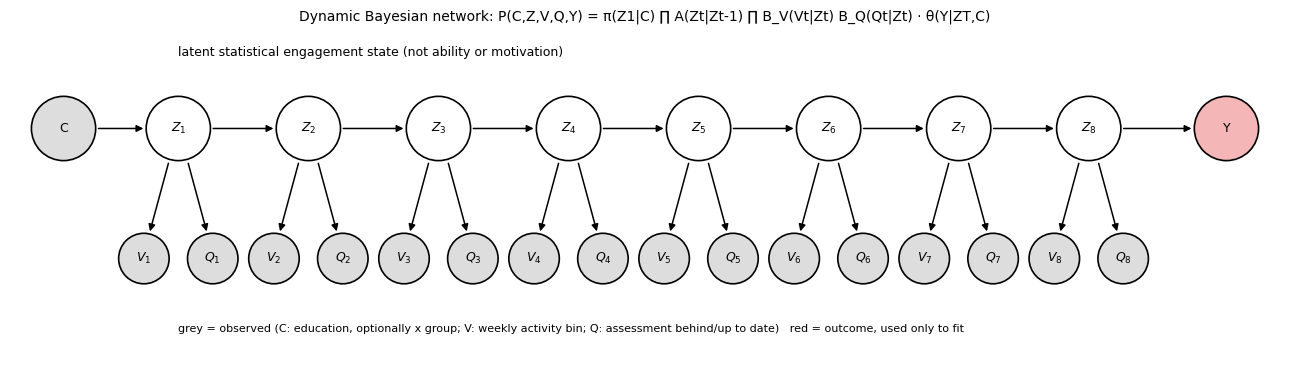

In [ ]:
def draw_dbn(T=8):
    fig, ax = plt.subplots(figsize=(13, 3.8)); ax.set_aspect("equal"); ax.axis("off")
    xs = 2.0 + np.arange(T) * 1.7; yz, yo = 2.4, 0.7
    def node(x, y, txt, fc, r=.42):
        ax.add_patch(plt.Circle((x, y), r, fc=fc, ec="k", lw=1.2)); ax.text(x, y, txt, ha="center", va="center", fontsize=9)
    def arrow(p, q): ax.annotate("", xy=q, xytext=p, arrowprops=dict(arrowstyle="-|>", lw=1.1, color="k"))
    node(0.5, yz, "C", "#dddddd")
    arrow((0.92, yz), (xs[0] - .42, yz))
    for t, x in enumerate(xs):
        node(x, yz, f"$Z_{{{t+1}}}$", "white")
        node(x - .45, yo, f"$V_{{{t+1}}}$", "#dddddd", .33); node(x + .45, yo, f"$Q_{{{t+1}}}$", "#dddddd", .33)
        arrow((x - .12, yz - .42), (x - .38, yo + .32)); arrow((x + .12, yz - .42), (x + .38, yo + .32))
        if t < T - 1: arrow((x + .42, yz), (xs[t + 1] - .42, yz))
    node(xs[-1] + 1.8, yz, "Y", "#f4b6b6"); arrow((xs[-1] + .42, yz), (xs[-1] + 1.38, yz))
    ax.text(xs[0], 3.35, "latent statistical engagement state (not ability or motivation)", fontsize=9, ha="left")
    ax.text(xs[0], -.25, "grey = observed (C: education, optionally x group; V: weekly activity bin; Q: assessment behind/up to date)   red = outcome, used only to fit", fontsize=8, ha="left")
    ax.set_xlim(-.2, xs[-1] + 2.5); ax.set_ylim(-.6, 3.7); ax.set_title("Dynamic Bayesian network: P(C,Z,V,Q,Y) = π(Z1|C) ∏ A(Zt|Zt-1) ∏ B_V(Vt|Zt) B_Q(Qt|Zt) · θ(Y|ZT,C)", fontsize=10)
    plt.tight_layout(); plt.show()


draw_dbn(sets["train"].W)

## 6. Alert policies at a fixed capacity (top 20% of currently eligible students per checkpoint; also 10% and 30%)
| policy | idea | needs protected attribute? |
|---|---|---|
| `topk` | rank by calibrated risk | no |
| `single_threshold` | one calibrated-probability threshold shared by all checkpoints | no |
| `indep_eopp` | per-checkpoint group offsets that equalise TPR (Hardt-style), each checkpoint tuned alone | yes |
| `temporal` | **proposed**: offsets *and* a re-alert discount ρ tuned jointly across checkpoints to shrink cumulative first-alert coverage gap, time-to-first-alert gap and false-alert burden, with smoothness penalties and a utility guard | yes |
| `coverage_only` | only the re-alert discount ρ | no |
| `temporal_nosmooth`, `temporal_rho0` | ablations: no smoothness penalties; offsets only (no ρ) | yes |

All are fit on **validation**, then replayed on test and on the transfer presentation, for every student-level split seed.

In [ ]:
import copy
POLS = ["topk", "single_threshold", "indep_eopp", "temporal", "coverage_only"]
ABLATIONS = ["temporal_nosmooth", "temporal_rho0"]
COLORS = dict(topk="gray", single_threshold="tab:orange", indep_eopp="tab:red", temporal="tab:blue", coverage_only="tab:green",
              temporal_nosmooth="tab:purple", temporal_rho0="tab:brown")


def eval_policies(S, cal, cap, pols, tag, keep=None):
    """Fit every policy on validation, replay on test and transfer. Returns one row per (set, policy)."""
    G_ = len(S["val"].group_names); Wk = np.array(S["val"].checkpoints, float); cf = copy.deepcopy(cfg); cf["policy"]["capacity"] = cap
    L = {k: logit(v) for k, v in cal.items()}; val = S["val"]
    fitted = fit_policies(L["val"], val.elig, val.y, val.gid, G_, Wk, cf, pols, MIN_CELL); rows = []
    for pn, pol in fitted.items():
        for s in ("test", "transfer"):
            c = S[s]; D = pol.apply(L[s], c.elig, c.gid)
            o = summary(D, c.elig, c.y, c.gid, G_, Wk, np.ones((1, c.n)), c.subtype, MIN_CELL)
            rows.append(dict(set=s, policy=pn, capacity=cap, needs_A=pol.needs_A, rho=pol.rho, n_nonzero_delta=0 if pol.delta is None else int((pol.delta != 0).sum()),
                             **tag, **scalar_table(o)))
            if keep is not None: keep[(pn, s)] = (D, L[s])
    return rows


rows = []; store = {}
for i, ss in enumerate(SPLIT_SEEDS):
    S = sets if i == 0 else make_sets(ss); cal, _ = scores_for("dbn", S, MODEL_SEED)
    for cap in CAPACITIES:
        rows += eval_policies(S, cal, cap, POLS + ABLATIONS if cap == CAP else POLS, dict(split=ss), keep=store if (i == 0 and cap == CAP) else None)
    print(f"split seed {ss} done")
R = pd.DataFrame(rows)
cols = ["dEOpp_mean", "covgap_all_final", "covgap_final", "cd_final", "ppv", "fa_expo", "rmtfa_gap", "repeat_frac", "ge2", "rho", "n_nonzero_delta"]
agg = R[R.capacity == CAP].groupby(["set", "policy"])[cols].agg(["mean", "std"]).round(3)
print(f"Mean and std over {len(SPLIT_SEEDS)} student-level split seeds (capacity {CAP:.0%}); std now reflects split variability."); display(agg.loc["test"])

split seed 2024 done
split seed 1 done
split seed 2 done
split seed 3 done
split seed 4 done
Mean and std over 5 student-level split seeds (capacity 20%); std now reflects split variability.


dEOpp_mean        covgap_all_final        covgap_final        cd_final           ppv        fa_expo        rmtfa_gap        repeat_frac           ge2         rho         \
                        mean    std             mean    std         mean    std     mean    std   mean    std    mean    std      mean    std        mean    std   mean    std mean    std   
policy                                                                                                                                                                                       
coverage_only          0.118  0.017            0.241  0.176        0.129  0.054    0.675  0.084  0.763  0.043   0.291  0.091     0.720  0.327       0.401  0.109  0.167  0.033  0.9  0.742   
indep_eopp             0.125  0.038            0.274  0.138        0.114  0.096    0.567  0.017  0.807  0.015   0.166  0.017     0.736  0.634       0.551  0.014  0.210  0.005  0.0  0.000   
single_threshold       0.112  0.026            0.226  0.159        0.082  0.020    0.594  0.037  0.795  0.026   0.192  0.027     0.668  0.260       0.529  0.031  0.222  0.031  0.0  0.000   
temporal               0.153  0.042            0.222  0.182        0.095  0.044    0.683  0.076  0.760  0.047   0.300  0.091     0.916  0.506       0.389  0.104  0.165  0.031  0.9  0.742   
temporal_nosmooth      0.200  0.045            0.247  0.172        0.114  0.054    0.669  0.101  0.750  0.078   0.295  0.149     0.850  0.380       0.401  0.162  0.171  0.048  0.9  1.245   
temporal_rho0          0.143  0.016            0.268  0.156        0.126  0.095    0.570  0.019  0.805  0.016   0.170  0.020     0.930  0.708       0.546  0.019  0.210  0.004  0.0  0.000   
topk                   0.126  0.032            0.235  0.173        0.088  0.067    0.568  0.026  0.811  0.016   0.164  0.016     0.605  0.360       0.552  0.015  0.209  0.003  0.0  0.000   

                  n_nonzero_delta         
                             mean    std  
policy                                    
coverage_only                 0.0  0.000  
indep_eopp                    4.4  3.050  
single_threshold              0.0  0.000  
temporal                      3.8  1.304  
temporal_nosmooth             5.4  1.517  
temporal_rho0                 3.6  1.949  
topk                          0.0  0.000

In [ ]:
VARIANTS = [
    ("baseline (3-state DBN)", dict()),
    ("ablation: LR scores, no latent state", dict(model="lr")),
    ("ablation: DBN with iid states (no transitions)", dict(model="dbn_iid")),
    ("ablation: DBN with fixed state (identity transitions)", dict(model="dbn_identity")),
    ("robustness: 2 latent states", dict(model="dbn_S2")),
    ("robustness: schedule 1-3-5-7", dict(ck=[1, 3, 5, 7])),
    ("robustness: schedule 3-5-7-9", dict(ck=[3, 5, 7, 9])),
    ("robustness: 30% of activity records dropped", dict(suppress=dict(frac=.3))),
    ("robustness: 30% dropped for disabled students only", dict(suppress=dict(frac=.3, group="disability"))),
    ("robustness: outcome = fail only", dict(outcome="fail_only")),
    ("robustness: outcome = withdrawn only", dict(outcome="withdrawn_only")),
    ("secondary: age x disability groups", dict(group_def="age_disability")),
]
VPOL = ["topk", "indep_eopp", "temporal", "coverage_only"]
rows = []
for name, v in VARIANTS:
    S = make_sets(SPLIT_SEEDS[0], ck=v.get("ck", CK), outcome=v.get("outcome", "adverse"), group_def=v.get("group_def", "gender_disability"), suppress=v.get("suppress"))
    cal, _ = scores_for(v.get("model", "dbn"), S, MODEL_SEED)
    c = S["test"]; pr = predictive_rows(cal["test"], c.y, c.elig, CAP)[-1]
    for r in eval_policies(S, cal, CAP, VPOL, dict(variant=name)):
        r.update(AP_last=pr["AP"], AUROC_last=pr["AUROC"], n_test=int(c.elig[:, 0].sum()), pos_rate=float(c.y[c.elig[:, 0]].mean())); rows.append(r)
    print("done:", name)
RV = pd.DataFrame(rows)
vc = ["AP_last", "AUROC_last", "pos_rate", "policy", "dEOpp_mean", "covgap_all_final", "cd_final", "ppv", "fa_expo", "rmtfa_gap", "repeat_frac", "rho"]
for s in ("test", "transfer"):
    print(f"\n=== ablations and robustness, {s}, capacity {CAP:.0%}, split seed {SPLIT_SEEDS[0]} ==="); display(RV[RV.set == s].set_index("variant")[vc].round(3))

done: baseline (3-state DBN)
done: ablation: LR scores, no latent state
done: ablation: DBN with iid states (no transitions)
done: ablation: DBN with fixed state (identity transitions)
done: robustness: 2 latent states
done: robustness: schedule 1-3-5-7
done: robustness: schedule 3-5-7-9
done: robustness: 30% of activity records dropped
done: robustness: 30% dropped for disabled students only
done: robustness: outcome = fail only
done: robustness: outcome = withdrawn only
done: secondary: age x disability groups

=== ablations and robustness, test, capacity 20%, split seed 2024 ===


,AP_last,AUROC_last,pos_rate,policy,dEOpp_mean,covgap_all_final,cd_final,ppv,fa_expo,rmtfa_gap,repeat_frac,rho
variant,,,,,,,,,,,,
baseline (3-state DBN),0.780,0.778,0.457,topk,0.154,0.140,0.593,0.826,0.168,0.851,0.536,0.0
baseline (3-state DBN),0.780,0.778,0.457,indep_eopp,0.130,0.270,0.583,0.817,0.173,1.757,0.537,0.0
baseline (3-state DBN),0.780,0.778,0.457,temporal,0.087,0.094,0.778,0.684,0.446,1.290,0.233,2.0
baseline (3-state DBN),0.780,0.778,0.457,coverage_only,0.116,0.097,0.773,0.692,0.435,1.051,0.244,2.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,topk,0.095,0.302,0.579,0.833,0.146,0.772,0.559,0.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,indep_eopp,0.080,0.413,0.572,0.822,0.148,0.780,0.562,0.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,temporal,0.089,0.333,0.787,0.712,0.394,1.401,0.265,2.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,coverage_only,0.052,0.278,0.785,0.718,0.386,1.093,0.271,2.0
ablation: DBN with iid states (no transitions),0.670,0.717,0.457,topk,0.122,0.140,0.546,0.575,0.308,1.304,0.465,0.0



=== ablations and robustness, transfer, capacity 20%, split seed 2024 ===


,AP_last,AUROC_last,pos_rate,policy,dEOpp_mean,covgap_all_final,cd_final,ppv,fa_expo,rmtfa_gap,repeat_frac,rho
variant,,,,,,,,,,,,
baseline (3-state DBN),0.780,0.778,0.457,topk,0.081,0.118,0.553,0.628,0.235,0.690,0.558,0.0
baseline (3-state DBN),0.780,0.778,0.457,indep_eopp,0.335,0.531,0.546,0.624,0.239,2.809,0.557,0.0
baseline (3-state DBN),0.780,0.778,0.457,temporal,0.191,0.108,0.871,0.501,0.609,1.881,0.109,2.0
baseline (3-state DBN),0.780,0.778,0.457,coverage_only,0.079,0.095,0.869,0.500,0.610,0.666,0.109,2.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,topk,0.098,0.108,0.559,0.630,0.222,0.830,0.565,0.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,indep_eopp,0.257,0.254,0.561,0.623,0.234,1.994,0.555,0.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,temporal,0.136,0.193,0.834,0.538,0.538,1.349,0.183,2.0
"ablation: LR scores, no latent state",0.794,0.786,0.457,coverage_only,0.090,0.177,0.832,0.537,0.538,0.416,0.184,2.0
ablation: DBN with iid states (no transitions),0.670,0.717,0.457,topk,0.070,0.271,0.583,0.476,0.324,0.892,0.471,0.0


**Column guide.** `dEOpp_mean`: mean checkpoint max−min TPR · `covgap_all_final`: max−min of P(≥1 alert by last week | Y=1) over *all* groups (small cells included) · `covgap_final`: same over supported groups only ·
`cd_final`: cumulative detection of eventual adverse outcomes · `ppv`: share of alerts that go to Y=1 · `fa_expo`: P(≥1 alert | Y=0), the stigma/burden exposure ·
`rmtfa_gap`: gap in restricted-mean time-to-first-alert (never = last week + 2) · `repeat_frac`, `ge2`: repeated-alert burden · `n_nonzero_delta`: number of non-zero group offsets the tuner chose.
The std over split seeds is real split variability; ρ selection can flip between splits.

In [ ]:
print("Transfer (later presentation), capacity 20%"); display(agg.loc["transfer"])
cap_cols = ["cd_final", "covgap_all_final", "dEOpp_mean", "fa_expo", "ppv", "repeat_frac", "rmtfa_gap"]
CAPT = R[R.set == "test"].groupby(["capacity", "policy"])[cap_cols].mean().round(3)
print("\nTest set, mean over splits, by support capacity"); display(CAPT)
print("\nTransfer set, mean over splits, by support capacity"); display(R[R.set == "transfer"].groupby(["capacity", "policy"])[cap_cols].mean().round(3))

Transfer (later presentation), capacity 20%


dEOpp_mean        covgap_all_final        covgap_final        cd_final           ppv        fa_expo        rmtfa_gap        repeat_frac           ge2         rho         \
                        mean    std             mean    std         mean    std     mean    std   mean    std    mean    std      mean    std        mean    std   mean    std mean    std   
policy                                                                                                                                                                                       
coverage_only          0.081  0.007            0.120  0.047        0.095  0.030    0.710  0.118  0.582  0.049   0.409  0.138     0.752  0.072       0.344  0.166  0.169  0.070  0.9  0.742   
indep_eopp             0.195  0.093            0.267  0.158        0.253  0.135    0.548  0.009  0.626  0.003   0.233  0.004     1.556  0.766       0.561  0.006  0.223  0.003  0.0  0.000   
single_threshold       0.090  0.006            0.107  0.008        0.102  0.009    0.488  0.017  0.661  0.017   0.215  0.016     0.771  0.100       0.457  0.047  0.160  0.031  0.0  0.000   
temporal               0.180  0.036            0.171  0.059        0.138  0.044    0.714  0.121  0.579  0.046   0.411  0.136     1.188  0.548       0.341  0.165  0.168  0.072  0.9  0.742   
temporal_nosmooth      0.197  0.024            0.161  0.052        0.122  0.034    0.675  0.146  0.580  0.064   0.378  0.170     1.004  0.331       0.386  0.204  0.185  0.079  0.9  1.245   
temporal_rho0          0.183  0.087            0.240  0.171        0.207  0.149    0.547  0.009  0.626  0.003   0.235  0.006     1.331  0.901       0.560  0.008  0.221  0.002  0.0  0.000   
topk                   0.077  0.005            0.120  0.006        0.102  0.005    0.551  0.010  0.628  0.003   0.234  0.002     0.699  0.021       0.559  0.006  0.221  0.002  0.0  0.000   

                  n_nonzero_delta         
                             mean    std  
policy                                    
coverage_only                 0.0  0.000  
indep_eopp                    4.4  3.050  
single_threshold              0.0  0.000  
temporal                      3.8  1.304  
temporal_nosmooth             5.4  1.517  
temporal_rho0                 3.6  1.949  
topk                          0.0  0.000


Test set, mean over splits, by support capacity


cd_final  covgap_all_final  dEOpp_mean  fa_expo    ppv  repeat_frac  rmtfa_gap
capacity policy                                                                                           
0.1      coverage_only         0.561             0.225       0.077    0.164  0.766        0.112      0.709
         indep_eopp            0.333             0.327       0.143    0.044  0.918        0.548      0.927
         single_threshold      0.366             0.309       0.120    0.035  0.933        0.525      0.694
         temporal              0.544             0.200       0.111    0.148  0.788        0.154      0.694
         topk                  0.326             0.349       0.120    0.041  0.923        0.560      0.717
0.2      coverage_only         0.675             0.241       0.118    0.291  0.763        0.401      0.720
         indep_eopp            0.567             0.274       0.125    0.166  0.807        0.551      0.736
         single_threshold      0.594             0.226       0.112    0.192  0.795        0.529      0.668
         temporal              0.683             0.222       0.153    0.300  0.760        0.389      0.916
         temporal_nosmooth     0.669             0.247       0.200    0.295  0.750        0.401      0.850
         temporal_rho0         0.570             0.268       0.143    0.170  0.805        0.546      0.930
         topk                  0.568             0.235       0.126    0.164  0.811        0.552      0.605
0.3      coverage_only         0.819             0.216       0.136    0.544  0.666        0.425      0.525
         indep_eopp            0.691             0.231       0.154    0.287  0.721        0.596      0.960
         single_threshold      0.689             0.219       0.098    0.277  0.721        0.613      0.685
         temporal              0.785             0.203       0.143    0.484  0.676        0.467      0.682
         topk                  0.688             0.230       0.103    0.278  0.724        0.601      0.691


Transfer set, mean over splits, by support capacity


cd_final  covgap_all_final  dEOpp_mean  fa_expo    ppv  repeat_frac  rmtfa_gap
capacity policy                                                                                           
0.1      coverage_only         0.576             0.126       0.083    0.247  0.595        0.072      0.638
         indep_eopp            0.380             0.398       0.250    0.112  0.735        0.471      2.478
         single_threshold      0.194             0.139       0.084    0.032  0.871        0.534      0.666
         temporal              0.567             0.221       0.127    0.237  0.610        0.096      1.333
         topk                  0.379             0.132       0.079    0.112  0.735        0.472      0.764
0.2      coverage_only         0.710             0.120       0.081    0.409  0.582        0.344      0.752
         indep_eopp            0.548             0.267       0.195    0.233  0.626        0.561      1.556
         single_threshold      0.488             0.107       0.090    0.215  0.661        0.457      0.771
         temporal              0.714             0.171       0.180    0.411  0.579        0.341      1.188
         temporal_nosmooth     0.675             0.161       0.197    0.378  0.580        0.386      1.004
         temporal_rho0         0.547             0.240       0.183    0.235  0.626        0.560      1.331
         topk                  0.551             0.120       0.077    0.234  0.628        0.559      0.699
0.3      coverage_only         0.856             0.087       0.093    0.658  0.513        0.384      0.602
         indep_eopp            0.640             0.250       0.195    0.326  0.556        0.629      1.531
         single_threshold      0.581             0.204       0.095    0.312  0.572        0.593      0.884
         temporal              0.802             0.127       0.138    0.580  0.523        0.442      0.900
         topk                  0.638             0.194       0.091    0.317  0.558        0.635      0.862

### Paired student-level bootstrap (split 0): `temporal` minus each baseline, test and transfer
Confirmatory family (Holm): **H1** coverage gap, **H2** detection non-inferiority (tolerance 0.02), **H3** time-to-first-alert gap, **H4** false-alert-exposure non-inferiority (tolerance 0.05). Fixed-model intervals = evaluation uncertainty only.

In [ ]:
FA_TOL = 0.05
SPECS = [  # key, extractor, family, non-inferiority tolerance, sign so that "larger is better" before the non-inferiority test
    ("covgap_final", lambda o: o["covgap"][:, -1], "H1", None, 1),
    ("cd_final", lambda o: o["cd"][:, -1], "H2", cfg["policy"]["utility_tol"], 1),
    ("rmtfa_gap", lambda o: o["rmtfa_gap"], "H3", None, 1),
    ("fa_expo", lambda o: o["fa_expo_all"], "H4", FA_TOL, -1),
    ("ppv", lambda o: o["ppv"], "exploratory", None, 1),
    ("repeat_frac", lambda o: o["repeat_frac"], "exploratory", None, 1),
    ("ge2", lambda o: o["ge2"], "exploratory", None, 1),
]


def boot_compare(setname, base, new="temporal", seed=7):
    c = sets[setname]; Wb = cluster_weights(c.meta.id_student.to_numpy(), N_BOOT, seed)
    S_ = {pn: summary(store[(pn, setname)][0], c.elig, c.y, c.gid, G, WEEKS, Wb, c.subtype, MIN_CELL) for pn in (new, base)}; res = []
    for k, f, fam, ni, sg in SPECS:
        d = f(S_[new]) - f(S_[base]); lo, hi = ci(d)
        res.append(dict(metric=k, diff=d[0], lo=lo, hi=hi, p=boot_p(sg * d, noninf=ni) if ni is not None else boot_p(d), family=fam))
    B = pd.DataFrame(res); m = B.family != "exploratory"; B.loc[m, "p_holm"] = holm(B.loc[m, "p"].to_numpy()); return B.round(3)


print("diff = temporal - baseline; negative is better for gaps and false-alert exposure.")
for base in ("indep_eopp", "topk"):
    for s in ("test", "transfer"):
        print(f"\n--- temporal vs {base}, {s}, split seed {SPLIT_SEEDS[0]} ---"); display(boot_compare(s, base))

diff = temporal - baseline; negative is better for gaps and false-alert exposure.

--- temporal vs indep_eopp, test, split seed 2024 ---


,metric,diff,lo,hi,p,family,p_holm
0,covgap_final,-0.173,-0.328,0.028,0.104,H1,0.312
1,cd_final,0.194,0.161,0.231,0.001,H2,0.004
2,rmtfa_gap,-0.467,-1.149,0.275,0.260,H3,0.519
3,fa_expo,0.273,0.233,0.310,1.000,H4,1.000
4,ppv,-0.133,-0.163,-0.099,0.002,exploratory,NaN
5,repeat_frac,-0.304,-0.328,-0.281,0.002,exploratory,NaN
6,ge2,-0.075,-0.092,-0.058,0.002,exploratory,NaN



--- temporal vs indep_eopp, transfer, split seed 2024 ---


,metric,diff,lo,hi,p,family,p_holm
0,covgap_final,-0.398,-0.548,-0.215,0.002,H1,0.006
1,cd_final,0.325,0.288,0.363,0.001,H2,0.004
2,rmtfa_gap,-0.928,-1.424,-0.338,0.002,H3,0.006
3,fa_expo,0.370,0.339,0.398,1.000,H4,1.000
4,ppv,-0.123,-0.154,-0.091,0.002,exploratory,NaN
5,repeat_frac,-0.448,-0.468,-0.426,0.002,exploratory,NaN
6,ge2,-0.168,-0.186,-0.149,0.002,exploratory,NaN



--- temporal vs topk, test, split seed 2024 ---


,metric,diff,lo,hi,p,family,p_holm
0,covgap_final,0.006,-0.153,0.114,0.851,H1,1.000
1,cd_final,0.185,0.151,0.222,0.001,H2,0.004
2,rmtfa_gap,0.439,-0.662,1.091,0.490,H3,1.000
3,fa_expo,0.279,0.240,0.315,1.000,H4,1.000
4,ppv,-0.142,-0.173,-0.109,0.002,exploratory,NaN
5,repeat_frac,-0.303,-0.326,-0.281,0.002,exploratory,NaN
6,ge2,-0.074,-0.091,-0.058,0.002,exploratory,NaN



--- temporal vs topk, transfer, split seed 2024 ---


,metric,diff,lo,hi,p,family,p_holm
0,covgap_final,-0.032,-0.152,0.083,0.559,H1,1.000
1,cd_final,0.318,0.282,0.355,0.001,H2,0.004
2,rmtfa_gap,1.191,0.467,1.819,0.010,H3,0.030
3,fa_expo,0.374,0.343,0.402,1.000,H4,1.000
4,ppv,-0.127,-0.156,-0.097,0.002,exploratory,NaN
5,repeat_frac,-0.449,-0.470,-0.427,0.002,exploratory,NaN
6,ge2,-0.171,-0.188,-0.153,0.002,exploratory,NaN


Groups with fewer than 30 positives or negatives are excluded from the headline max−min gaps (`covgap_final`) but **never dropped**: `covgap_all_final` and the table below include them.

In [ ]:
def group_report(setname, pol):
    c = sets[setname]; D = store[(pol, setname)][0] & c.elig
    o = summary(D, c.elig, c.y, c.gid, G, WEEKS, np.ones((1, c.n)), c.subtype, MIN_CELL)
    ever = D.any(1); co = c.elig[:, 0]
    t = pd.DataFrame(dict(group=gn, n_pos=o["cov_den"], n_neg=o["cov_den_neg"], exploratory=(o["cov_den"] < MIN_CELL) | (o["cov_den_neg"] < MIN_CELL),
                          cum_coverage=o["cov"][0, :, -1], mean_weeks_to_first_alert=o["rmtfa"][0], alerts_per_student=o["alerts_ps"][0], false_alert_exposure=o["fa_expo"][0]))
    t["coverage_minus_overall"] = t.cum_coverage - o["cd"][0, -1]; t["false_exposure_minus_overall"] = t.false_alert_exposure - o["fa_expo_all"][0]
    for sub in ("Fail", "Withdrawn"):
        ms = [co & (c.gid == g) & (c.subtype == sub) for g in range(G)]
        t[f"n_{sub.lower()}"] = [int(m.sum()) for m in ms]; t[f"coverage_{sub.lower()}"] = [ever[m].mean() if m.any() else np.nan for m in ms]
    return t.round(3)


for pol in ("topk", "indep_eopp", "temporal"):
    print(f"\n=== {pol}, test (signed gaps: positive = group above the overall rate) ==="); display(group_report("test", pol))
print("\n=== temporal, transfer ==="); display(group_report("transfer", "temporal"))


=== topk, test (signed gaps: positive = group above the overall rate) ===


,group,n_pos,n_neg,exploratory,cum_coverage,mean_weeks_to_first_alert,alerts_per_student,false_alert_exposure,coverage_minus_overall,false_exposure_minus_overall,n_fail,coverage_fail,n_withdrawn,coverage_withdrawn
0,F|N,330.0,426.0,False,0.585,6.364,0.720,0.169,-0.008,0.001,214,0.650,116,0.466
1,F|Y,41.0,35.0,False,0.659,5.512,0.947,0.143,0.066,-0.025,23,0.652,18,0.667
2,M|N,54.0,45.0,False,0.574,6.148,1.040,0.178,-0.019,0.010,40,0.675,14,0.286
3,M|Y,7.0,7.0,True,0.714,4.571,1.286,0.143,0.122,-0.025,4,0.500,3,1.000



=== indep_eopp, test (signed gaps: positive = group above the overall rate) ===


,group,n_pos,n_neg,exploratory,cum_coverage,mean_weeks_to_first_alert,alerts_per_student,false_alert_exposure,coverage_minus_overall,false_exposure_minus_overall,n_fail,coverage_fail,n_withdrawn,coverage_withdrawn
0,F|N,330.0,426.0,False,0.588,6.267,0.745,0.174,0.005,0.000,214,0.645,116,0.483
1,F|Y,41.0,35.0,False,0.707,5.317,1.079,0.257,0.124,0.084,23,0.696,18,0.722
2,M|N,54.0,45.0,False,0.444,7.074,0.747,0.111,-0.139,-0.062,40,0.500,14,0.286
3,M|Y,7.0,7.0,True,0.714,4.857,1.286,0.143,0.131,-0.031,4,0.500,3,1.000



=== temporal, test (signed gaps: positive = group above the overall rate) ===


,group,n_pos,n_neg,exploratory,cum_coverage,mean_weeks_to_first_alert,alerts_per_student,false_alert_exposure,coverage_minus_overall,false_exposure_minus_overall,n_fail,coverage_fail,n_withdrawn,coverage_withdrawn
0,F|N,330.0,426.0,False,0.764,5.509,0.746,0.434,-0.014,-0.012,214,0.822,116,0.655
1,F|Y,41.0,35.0,False,0.854,4.488,0.947,0.571,0.076,0.125,23,0.826,18,0.889
2,M|N,54.0,45.0,False,0.796,5.778,0.848,0.400,0.019,-0.046,40,0.875,14,0.571
3,M|Y,7.0,7.0,True,0.857,4.286,1.214,0.857,0.079,0.411,4,0.750,3,1.000



=== temporal, transfer ===


,group,n_pos,n_neg,exploratory,cum_coverage,mean_weeks_to_first_alert,alerts_per_student,false_alert_exposure,coverage_minus_overall,false_exposure_minus_overall,n_fail,coverage_fail,n_withdrawn,coverage_withdrawn
0,F|N,486.0,918.0,False,0.879,4.996,0.794,0.605,0.008,-0.004,294,0.901,192,0.844
1,F|Y,48.0,59.0,False,0.875,5.000,0.766,0.610,0.004,0.001,27,0.926,21,0.810
2,M|N,73.0,116.0,False,0.808,6.877,0.746,0.647,-0.063,0.038,40,0.825,33,0.788
3,M|Y,12.0,11.0,True,0.917,5.167,0.913,0.545,0.046,-0.063,8,1.000,4,0.750


## 7. Plots

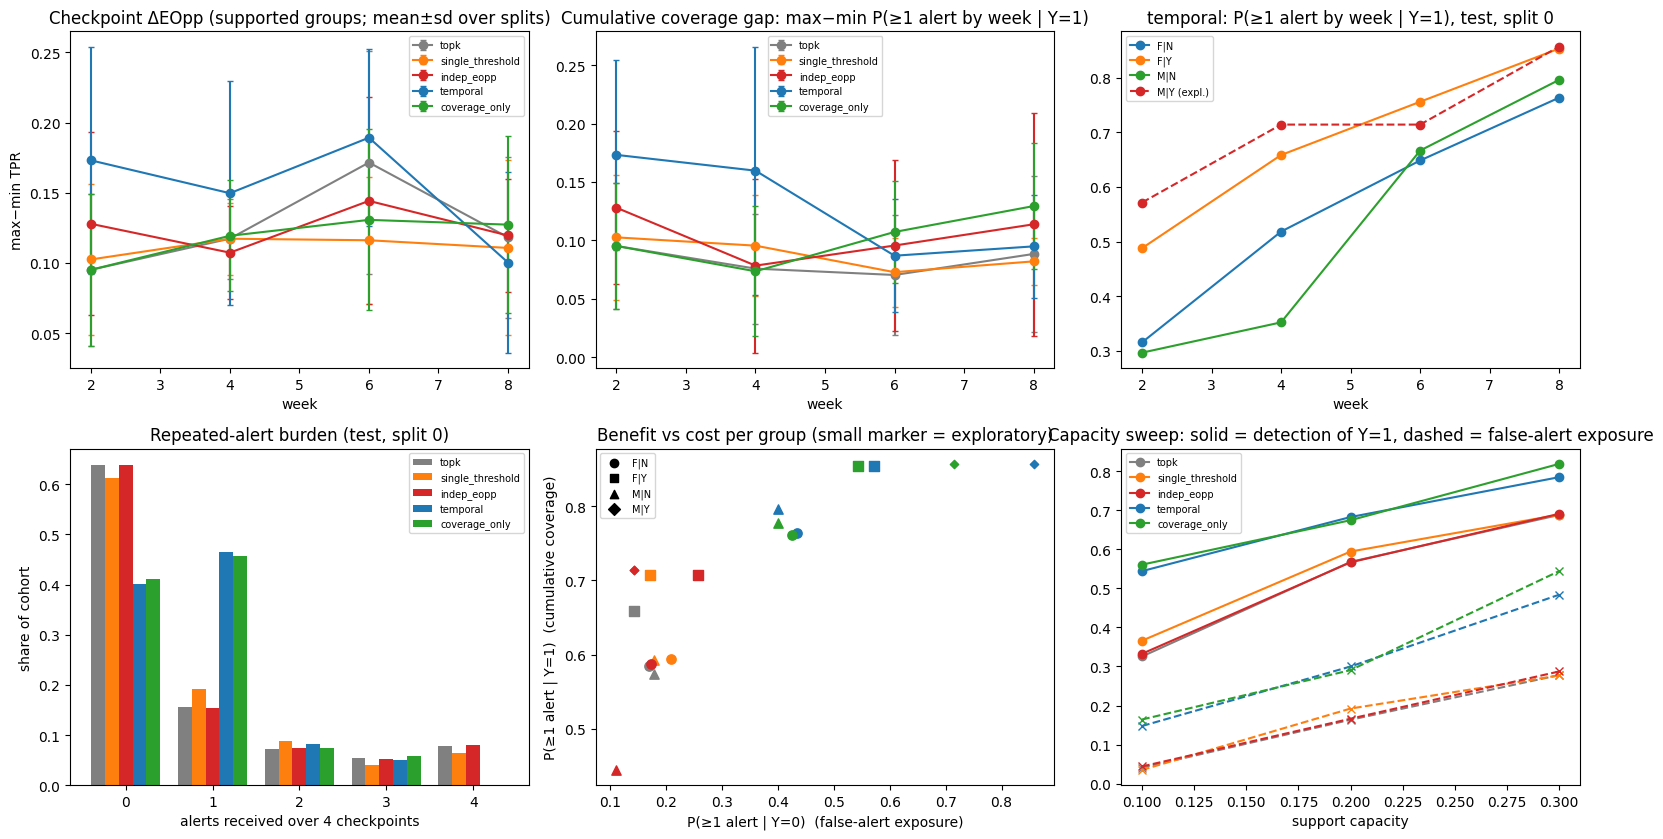

In [ ]:
d0 = R[(R.set == "test") & (R.capacity == CAP)]
OO = {pn: summary(store[(pn, "test")][0], te.elig, te.y, te.gid, G, WEEKS, np.ones((1, te.n)), te.subtype, MIN_CELL) for pn in POLS}
fig, ax = plt.subplots(2, 3, figsize=(16, 8.5))
for pn in POLS:
    dd = d0[d0.policy == pn]
    ax[0, 0].errorbar(CK, [dd[f"dEOpp_c{j}"].mean() for j in range(len(CK))], yerr=[dd[f"dEOpp_c{j}"].std() for j in range(len(CK))], label=pn, color=COLORS[pn], marker="o", capsize=2)
    ax[0, 1].errorbar(CK, [dd[f"covgap_c{j}"].mean() for j in range(len(CK))], yerr=[dd[f"covgap_c{j}"].std() for j in range(len(CK))], label=pn, color=COLORS[pn], marker="o", capsize=2)
ax[0, 0].set(title="Checkpoint ΔEOpp (supported groups; mean±sd over splits)", xlabel="week", ylabel="max−min TPR"); ax[0, 0].legend(fontsize=7)
ax[0, 1].set(title="Cumulative coverage gap: max−min P(≥1 alert by week | Y=1)", xlabel="week"); ax[0, 1].legend(fontsize=7)
for g, nm in enumerate(gn):
    exp = (OO["temporal"]["cov_den"][g] < MIN_CELL) or (OO["temporal"]["cov_den_neg"][g] < MIN_CELL)
    ax[0, 2].plot(CK, OO["temporal"]["cov"][0, g], "--" if exp else "-", marker="o", label=nm + (" (expl.)" if exp else ""))
ax[0, 2].set(title="temporal: P(≥1 alert by week | Y=1), test, split 0", xlabel="week"); ax[0, 2].legend(fontsize=7)
w = .16
for i, pn in enumerate(POLS):
    cnt = (store[(pn, "test")][0] & te.elig).sum(1)[te.elig[:, 0]]; ax[1, 0].bar(np.arange(5) + i * w - .32, [(cnt == k).mean() for k in range(5)], w, label=pn, color=COLORS[pn])
ax[1, 0].set(title="Repeated-alert burden (test, split 0)", xlabel="alerts received over 4 checkpoints", ylabel="share of cohort"); ax[1, 0].legend(fontsize=7)
mk = ["o", "s", "^", "D", "v", "P"]
for pn in POLS:
    for g in range(G): ax[1, 1].scatter(OO[pn]["fa_expo"][0, g], OO[pn]["cov"][0, g, -1], color=COLORS[pn], marker=mk[g % 6], s=45 if OO[pn]["cov_den"][g] >= MIN_CELL else 18)
for g, nm in enumerate(gn): ax[1, 1].scatter([], [], color="k", marker=mk[g % 6], label=nm)
ax[1, 1].set(title="Benefit vs cost per group (small marker = exploratory)", xlabel="P(≥1 alert | Y=0)  (false-alert exposure)", ylabel="P(≥1 alert | Y=1)  (cumulative coverage)"); ax[1, 1].legend(fontsize=7)
ct = R[R.set == "test"].groupby(["capacity", "policy"])[["cd_final", "fa_expo"]].mean().reset_index()
for pn in POLS:
    q = ct[ct.policy == pn]; ax[1, 2].plot(q.capacity, q.cd_final, "-o", color=COLORS[pn], label=pn); ax[1, 2].plot(q.capacity, q.fa_expo, "--x", color=COLORS[pn])
ax[1, 2].set(title="Capacity sweep: solid = detection of Y=1, dashed = false-alert exposure", xlabel="support capacity"); ax[1, 2].legend(fontsize=7)
if SYNTHETIC: fig.text(.5, .5, "SYNTHETIC DATA", ha="center", va="center", fontsize=40, alpha=.08, rotation=20)
plt.tight_layout(); plt.show()

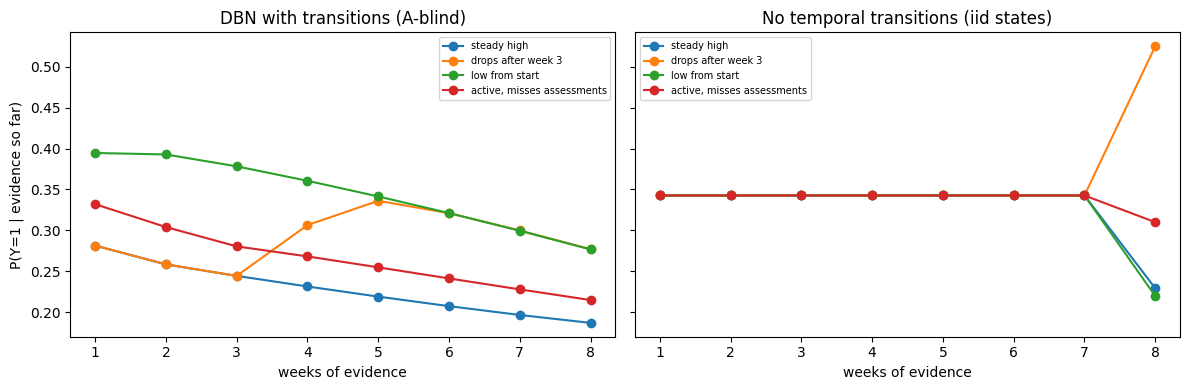


=== dbn: behaviour on activity / assessment slices (test, top 20% alerts) ===


base_rate                      alert_rate                         TPR                         FPR                       AUROC                     
week                                   2      4      6      8          2      4      6      8      2      4      6      8      2      4      6      8      2      4      6      8
slice                                                                                                                                                                            
all                                0.457  0.449  0.439  0.428      0.200  0.200  0.200  0.200  0.333  0.352  0.386  0.424  0.088  0.076  0.055  0.031  0.728  0.731  0.760  0.778
higher activity                    0.387  0.380  0.360  0.331      0.037  0.065  0.079  0.084  0.084  0.136  0.191  0.212  0.007  0.021  0.016  0.020  0.689  0.688  0.709  0.697
low activity (bottom quartile)     0.662  0.653  0.672  0.714      0.679  0.597  0.556  0.542  0.761  0.721  0.692  0.716  0.519  0.366  0.276  0.108  0.691  0.749  0.786  0.857
missing assessment                 0.750  0.908  0.849  0.450      0.583  0.939  0.835  0.254  0.722  0.933  0.881  0.513  0.167  1.000  0.571  0.041  0.814  0.689  0.825  0.804
no missing assessment              0.441  0.395  0.366  0.346      0.179  0.113  0.086  0.000  0.298  0.195  0.180  0.000  0.086  0.060  0.033  0.000  0.715  0.680  0.698  0.659


=== lr: behaviour on activity / assessment slices (test, top 20% alerts) ===


base_rate                      alert_rate                         TPR                         FPR                       AUROC                     
week                                   2      4      6      8          2      4      6      8      2      4      6      8      2      4      6      8      2      4      6      8
slice                                                                                                                                                                            
all                                0.457  0.449  0.439  0.428      0.200  0.200  0.200  0.200  0.340  0.364  0.378  0.424  0.082  0.066  0.060  0.031  0.726  0.754  0.782  0.786
higher activity                    0.387  0.380  0.360  0.331      0.052  0.082  0.097  0.067  0.095  0.178  0.211  0.189  0.025  0.023  0.032  0.007  0.680  0.714  0.731  0.703
low activity (bottom quartile)     0.662  0.653  0.672  0.714      0.633  0.547  0.504  0.590  0.761  0.682  0.641  0.747  0.383  0.293  0.224  0.200  0.745  0.771  0.803  0.852
missing assessment                 0.750  0.908  0.849  0.450      0.979  1.000  0.914  0.238  1.000  1.000  0.941  0.487  0.917  1.000  0.762  0.034  0.810  0.776  0.833  0.835
no missing assessment              0.441  0.395  0.366  0.346      0.158  0.106  0.072  0.058  0.280  0.191  0.144  0.121  0.062  0.050  0.030  0.024  0.717  0.701  0.721  0.636

In [ ]:
m_iid = scores_for("dbn_iid", sets, MODEL_SEED)[1]
pat = lambda T: {"steady high": (np.full(T, 4), np.zeros(T, int)), "drops after week 3": (np.array([4] * 3 + [0] * (T - 3)), np.zeros(T, int)),
                 "low from start": (np.full(T, 1), np.zeros(T, int)), "active, misses assessments": (np.full(T, 3), np.array([-1] * 3 + [1] * (T - 3)))}
fig, axs = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for a, (mm, ttl) in zip(axs, ((dbn0, "DBN with transitions (A-blind)"), (m_iid, "No temporal transitions (iid states)"))):
    T = mm.T
    for nm, (v, q) in pat(T).items():
        r = [mm.risk(v[None], q[None], (np.arange(1, T + 1) <= t)[None], np.array([1]), [t])[0, 0] for t in range(1, T + 1)]; a.plot(range(1, T + 1), r, marker="o", label=nm)
    a.set(xlabel="weeks of evidence", title=ttl); a.legend(fontsize=7)
axs[0].set_ylabel("P(Y=1 | evidence so far)"); plt.tight_layout(); plt.show()

# ---- behaviour on low-activity students and students with missing assessments (test set) ----
rows = []
for nm in ("lr", "dbn"):
    sc = CAL[nm][0]["test"]
    for j, t in enumerate(CK):
        e = te.elig[:, j]; cum = te.clicks[:, :t].sum(1); q25 = np.quantile(cum[e], .25); idx = np.flatnonzero(e)
        k = int(round(CAP * e.sum())); top = np.zeros(te.n, bool); top[idx[np.argsort(-sc[idx, j], kind="stable")[:k]]] = True
        sl = {"all": e, "low activity (bottom quartile)": e & (cum <= q25), "higher activity": e & (cum > q25),
              "missing assessment": e & (te.nmiss[:, t - 1] > 0), "no missing assessment": e & (te.nmiss[:, t - 1] == 0)}
        for sn, m_ in sl.items():
            if m_.sum() < MIN_CELL or len(np.unique(te.y[m_])) < 2: continue
            rows.append(dict(model=nm, week=t, slice=sn, n=int(m_.sum()), base_rate=te.y[m_].mean(), AUROC=roc_auc_score(te.y[m_], sc[m_, j]),
                             alert_rate=top[m_].mean(), TPR=top[m_ & (te.y == 1)].sum() / max((m_ & (te.y == 1)).sum(), 1),
                             FPR=top[m_ & (te.y == 0)].sum() / max((m_ & (te.y == 0)).sum(), 1)))
SL = pd.DataFrame(rows)
for nm in ("dbn", "lr"):
    print(f"\n=== {nm}: behaviour on activity / assessment slices (test, top {CAP:.0%} alerts) ==="); display(SL[SL.model == nm].pivot(index="slice", columns="week", values=["base_rate", "alert_rate", "TPR", "FPR", "AUROC"]).round(3))

## Reading the results responsibly
* **Latent state ≠ ability or motivation.** It summarises recorded activity; low clicks may reflect offline study, assistive technology, work commitments or inaccessible materials. The activity-suppression and low-activity-slice tables show how much the alerts depend on recorded activity alone.
* **Static vs dynamic.** Compare the DBN with LR, GBT and the static BN on AP/AUROC *and* on held-out weekly likelihood; they answer different questions. The dynamic model's likelihood advantage does not by itself mean better detection.
* **Seeds vs splits.** Model seeds barely change EM; the spread reported in the tables comes from re-drawing the student-level split. Small groups (gender × disability cells under 30 positives or negatives) stay exploratory and their gaps are biased upward by sampling noise.
* **Cumulative detection is gameable.** A re-alert discount reaches more distinct students under a fixed capacity, which raises detection of Y=1 *and* false-alert exposure (P(≥1 alert | Y=0)). Read `cd_final` only together with `ppv`, `fa_expo` and `repeat_frac`, and look at signed per-group gaps, not just max−min.
* **Fairness at a checkpoint is not fairness of the alert history.** Per-checkpoint equalisation can widen cumulative coverage gaps or fail to transfer to a later presentation; compare `indep_eopp` with `temporal` on both.
* **Ethics.** Repeated alerts can stigmatise; support must stay voluntary, with an opt-out and a way to contest an alert. Low platform activity is evidence about *recorded* behaviour, not proof of need, and a group receiving more alerts is not automatically better served. The learned structure is not causal.

In [ ]:
FINAL = R[R.capacity == CAP].groupby(["set", "policy"])[["cd_final", "covgap_all_final", "covgap_final", "dEOpp_mean", "fa_expo", "ppv", "repeat_frac", "ge2", "rmtfa_gap", "rho"]].mean().round(3)
print(f"Summary at {CAP:.0%} capacity, mean over {len(SPLIT_SEEDS)} student-level splits"); display(FINAL)

Summary at 20% capacity, mean over 5 student-level splits


cd_final  covgap_all_final  covgap_final  dEOpp_mean  fa_expo    ppv  repeat_frac    ge2  rmtfa_gap  rho
set      policy                                                                                                                     
test     coverage_only         0.675             0.241         0.129       0.118    0.291  0.763        0.401  0.167      0.720  0.9
         indep_eopp            0.567             0.274         0.114       0.125    0.166  0.807        0.551  0.210      0.736  0.0
         single_threshold      0.594             0.226         0.082       0.112    0.192  0.795        0.529  0.222      0.668  0.0
         temporal              0.683             0.222         0.095       0.153    0.300  0.760        0.389  0.165      0.916  0.9
         temporal_nosmooth     0.669             0.247         0.114       0.200    0.295  0.750        0.401  0.171      0.850  0.9
         temporal_rho0         0.570             0.268         0.126       0.143    0.170  0.805        0.546  0.210      0.930  0.0
         topk                  0.568             0.235         0.088       0.126    0.164  0.811        0.552  0.209      0.605  0.0
transfer coverage_only         0.710             0.120         0.095       0.081    0.409  0.582        0.344  0.169      0.752  0.9
         indep_eopp            0.548             0.267         0.253       0.195    0.233  0.626        0.561  0.223      1.556  0.0
         single_threshold      0.488             0.107         0.102       0.090    0.215  0.661        0.457  0.160      0.771  0.0
         temporal              0.714             0.171         0.138       0.180    0.411  0.579        0.341  0.168      1.188  0.9
         temporal_nosmooth     0.675             0.161         0.122       0.197    0.378  0.580        0.386  0.185      1.004  0.9
         temporal_rho0         0.547             0.240         0.207       0.183    0.235  0.626        0.560  0.221      1.331  0.0
         topk                  0.551             0.120         0.102       0.077    0.234  0.628        0.559  0.221      0.699  0.0

In [ ]:
# ===== CELL A: dependency check and output folder =====
RES = Path("results"); RES.mkdir(exist_ok=True)
needed = ["sets","CAL","R","cfg","CK","WEEKS","CAP","SPLIT_SEEDS","MODEL_SEED","MIN_CELL",
          "N_BOOT","G","te","dbn0","make_sets","scores_for","eval_policies","fit_policies",
          "summary","run_policy","logit","predictive_rows","cluster_weights","ci","boot_p",
          "holm","SPECS","check_agreement","dbn_inputs","cov_index","draw_dbn","MODELS",
          "POLS","Z0","tune_indep","tune_temporal","display"]
missing = [n for n in needed if n not in globals()]
assert not missing, f"Run the original notebook first. Missing: {missing}"
print("OK: earlier variables present. Outputs go to ./results")

OK: earlier variables present. Outputs go to ./results


In [ ]:
# ===== CELL B: log loss and Brier score (fills the empty table column) =====
rows = []
for nm in MODELS:
    for s in ("test", "transfer"):
        c = sets[s]
        for r in predictive_rows(CAL[nm][0][s], c.y, c.elig, CAP):
            rows.append(dict(model=nm, set=s, week=CK[r["checkpoint"]],
                             logloss=r["logloss"], brier=r["brier"]))
LL = pd.DataFrame(rows); LL.to_csv(RES / "logloss_brier.csv", index=False)
for metric in ("logloss", "brier"):
    print(f"\n=== {metric} (lower is better) ===")
    display(LL.pivot_table(index=["set", "week"], columns="model", values=metric).round(3))
d = LL[(LL.model == "dbn") & (LL.set == "test")]
print(f"\nTable row (DBN scores, test, mean over checkpoints): "
      f"logloss {d.logloss.mean():.3f}, Brier {d.brier.mean():.3f}")
print("Note: the policy rows of the table all use the DBN's probabilities, so they share these values.")


=== logloss (lower is better) ===


model            dbn    gbt     lr  static_bn
set      week                                
test     2     0.609  0.611  0.611      0.623
         4     0.599  0.578  0.580      0.603
         6     0.568  0.540  0.546      0.585
         8     0.529  0.507  0.523      0.540
transfer 2     0.654  0.633  0.628      0.645
         4     0.594  0.587  0.583      0.603
         6     0.580  0.577  0.573      0.590
         8     0.543  0.541  0.532      0.574


=== brier (lower is better) ===


model            dbn    gbt     lr  static_bn
set      week                                
test     2     0.210  0.210  0.210      0.217
         4     0.207  0.198  0.199      0.209
         6     0.195  0.182  0.184      0.201
         8     0.179  0.169  0.175      0.181
transfer 2     0.229  0.221  0.219      0.227
         4     0.205  0.201  0.200      0.208
         6     0.198  0.198  0.196      0.202
         8     0.181  0.182  0.176      0.196


Table row (DBN scores, test, mean over checkpoints): logloss 0.576, Brier 0.198
Note: the policy rows of the table all use the DBN's probabilities, so they share these values.


In [ ]:
# ===== CELL C: five model seeds (DBN initialisation), split seed fixed =====
rows = []
for s in range(5):
    cal_s, _ = scores_for("dbn", sets, s)
    rows += eval_policies(sets, cal_s, CAP, ["indep_eopp", "temporal"], dict(model_seed=s))
MS = pd.DataFrame(rows); MS.to_csv(RES / "model_seeds.csv", index=False)
cols = ["cd_final", "covgap_all_final", "covgap_final", "dEOpp_mean", "fa_expo"]
print(f"Five model seeds, split seed {SPLIT_SEEDS[0]}, capacity {CAP:.0%}")
display(MS.groupby(["set", "policy"])[cols].agg(["mean", "std"]).round(3))

Five model seeds, split seed 2024, capacity 20%


cd_final      covgap_all_final      covgap_final      dEOpp_mean      fa_expo     
                        mean  std             mean  std         mean  std       mean  std    mean  std
set      policy                                                                                       
test     indep_eopp    0.583  0.0            0.270  0.0        0.263  0.0      0.130  0.0   0.173  0.0
         temporal      0.778  0.0            0.094  0.0        0.090  0.0      0.087  0.0   0.446  0.0
transfer indep_eopp    0.546  0.0            0.531  0.0        0.468  0.0      0.334  0.0   0.238  0.0
         temporal      0.871  0.0            0.108  0.0        0.070  0.0      0.190  0.0   0.609  0.0

In [ ]:
# ===== CELL D: paired student-level bootstrap on EVERY split seed =====
# Note: for H2 and H4, p is the non-inferiority p-value (small = margin holds).
split_rows = []
for i, ss in enumerate(SPLIT_SEEDS):
    S = sets if i == 0 else make_sets(ss)
    cal, _ = scores_for("dbn", S, MODEL_SEED)
    keep = {}
    eval_policies(S, cal, CAP, ["topk", "indep_eopp", "temporal"], dict(split=ss), keep=keep)
    for setname in ("test", "transfer"):
        c = S[setname]
        Wb = cluster_weights(c.meta.id_student.to_numpy(), N_BOOT, 7)
        def sumf(D, c=c, Wb=Wb):
            return summary(D, c.elig, c.y, c.gid, G, WEEKS, Wb, subtype=c.subtype, min_cell=MIN_CELL)
        Sn = sumf(keep[("temporal", setname)][0])
        for base in ("indep_eopp", "topk"):
            Sb = sumf(keep[(base, setname)][0])
            out = []
            for k, f, fam, ni, sg in SPECS:
                d = f(Sn) - f(Sb); lo, hi = ci(d)
                p = boot_p(sg * d, noninf=ni) if ni is not None else boot_p(sg * d)
                out.append(dict(split=ss, set=setname, base=base, metric=k, family=fam,
                                diff=d[0], lo=lo, hi=hi, p=p))
            B_ = pd.DataFrame(out); m = B_.family != "exploratory"
            B_["p_holm"] = np.nan
            B_.loc[m, "p_holm"] = holm(B_.loc[m, "p"].to_numpy())
            split_rows.append(B_)
PB = pd.concat(split_rows, ignore_index=True)
PB.to_csv(RES / "paired_bootstrap_all_splits.csv", index=False)
Hm = PB[PB.family.str.startswith("H")]
summ = Hm.groupby(["set", "base", "metric"]).agg(
    mean_diff=("diff", "mean"), sd_diff=("diff", "std"),
    splits_holm_p_below_05=("p_holm", lambda p: int((p < 0.05).sum())),
    n_splits=("p_holm", "count")).round(3)
print("Temporal minus baseline, mean over splits (negative is better for gaps and false-alert exposure)")
display(summ)
print("Split-0 test rows (should match the earlier printout, up to bootstrap noise):")
display(PB[(PB.split == SPLIT_SEEDS[0]) & (PB.set == "test") & (PB.base == "indep_eopp")].round(3))

Temporal minus baseline, mean over splits (negative is better for gaps and false-alert exposure)


mean_diff  sd_diff  splits_holm_p_below_05  n_splits
set      base       metric                                                            
test     indep_eopp cd_final          0.116    0.066                       5         5
                    covgap_final     -0.019    0.088                       0         5
                    fa_expo           0.134    0.093                       1         5
                    rmtfa_gap         0.180    0.437                       0         5
         topk       cd_final          0.115    0.059                       5         5
                    covgap_final      0.006    0.087                       0         5
                    fa_expo           0.136    0.095                       1         5
                    rmtfa_gap         0.311    0.736                       0         5
transfer indep_eopp cd_final          0.166    0.122                       5         5
                    covgap_final     -0.114    0.164                       1         5
                    fa_expo           0.178    0.134                       1         5
                    rmtfa_gap        -0.368    0.440                       1         5
         topk       cd_final          0.163    0.120                       5         5
                    covgap_final      0.036    0.047                       0         5
                    fa_expo           0.177    0.136                       1         5
                    rmtfa_gap         0.489    0.562                       1         5

Split-0 test rows (should match the earlier printout, up to bootstrap noise):


,split,set,base,metric,family,diff,lo,hi,p,p_holm
0,2024,test,indep_eopp,covgap_final,H1,-0.173,-0.328,0.028,0.104,0.312
1,2024,test,indep_eopp,cd_final,H2,0.194,0.161,0.231,0.001,0.004
2,2024,test,indep_eopp,rmtfa_gap,H3,-0.467,-1.149,0.275,0.260,0.519
3,2024,test,indep_eopp,fa_expo,H4,0.273,0.233,0.310,1.000,1.000
4,2024,test,indep_eopp,ppv,exploratory,-0.133,-0.163,-0.099,0.002,NaN
5,2024,test,indep_eopp,repeat_frac,exploratory,-0.304,-0.328,-0.281,0.002,NaN
6,2024,test,indep_eopp,ge2,exploratory,-0.075,-0.092,-0.058,0.002,NaN


In [ ]:
# ===== CELL E: does giving the group to the DBN change alerts? (recomputed) =====
calA, dbnA = scores_for("dbn_A", sets, MODEL_SEED)
Db = run_policy(logit(CAL["dbn"][0]["test"]), te.elig, te.gid, Z0, 0., CAP)
Da = run_policy(logit(calA["test"]), te.elig, te.gid, Z0, 0., CAP)
changed = (Db ^ Da).sum(0); union = (Db | Da).sum(0)
tab = pd.DataFrame({"week": CK, "alerts_A_blind": Db.sum(0), "alerts_with_A": Da.sum(0),
                    "changed_alerts": changed,
                    "share_of_union_changed": np.round(changed / np.maximum(union, 1), 3)})
display(tab)
tab.to_csv(RES / "group_input_alert_changes.csv", index=False)

,week,alerts_A_blind,alerts_with_A,changed_alerts,share_of_union_changed
0,2,189,189,26,0.129
1,4,186,186,44,0.212
2,6,183,183,64,0.298
3,8,179,179,18,0.096


In [ ]:
# ===== CELL F: tuning budgets (objective evaluations) and chosen offsets =====
Lv = logit(CAL["dbn"][0]["val"]); val = sets["val"]
cfg_cap = dict(cfg, policy=dict(cfg["policy"], capacity=CAP))
d_i, n_i = tune_indep(Lv, val.elig, val.y, val.gid, G, cfg_cap)
d_t, r_t, n_t, best_t = tune_temporal(Lv, val.elig, val.y, val.gid, G, WEEKS, cfg_cap)
print(f"indep_eopp objective evaluations: {n_i}")
print(f"temporal objective evaluations:  {n_t}")
print(f"temporal rho = {r_t}; non-zero offsets: {int((np.abs(d_t) > 0).sum())} of {d_t.size}")
print(f"indep non-zero offsets:          {int((np.abs(d_i) > 0).sum())} of {d_i.size}")
print("temporal offsets (rows = groups in gn order, cols = checkpoints):")
print(np.round(d_t, 3))

indep_eopp objective evaluations: 200
temporal objective evaluations:  315
temporal rho = 2; non-zero offsets: 3 of 16
indep non-zero offsets:          8 of 16
temporal offsets (rows = groups in gn order, cols = checkpoints):
[[ 0.     0.     0.     0.   ]
 [ 0.     0.     0.     0.   ]
 [-0.5   -0.417 -0.333  0.   ]
 [ 0.     0.     0.     0.   ]]


In [ ]:
# ===== CELL G: exact-inference agreement with an explicit tolerance =====
TOL = 1e-10
V_, Q_, o_ = dbn_inputs(te, dbn0.edges, dbn0.KV)
cov0 = cov_index(te, False)
rng = np.random.default_rng(0)
idx = rng.choice(np.flatnonzero(te.elig[:, 0]), 20, replace=False)
worst = {}
for i in idx:
    for t in CK:
        res = check_agreement(dbn0, V_[i], Q_[i], o_[i], cov0[i], t)
        for k, v in res.items():
            worst[k] = max(worst.get(k, 0.0), float(np.max(np.abs(v))))
for k, v in worst.items():
    print(f"{k:12s} max |diff| = {v:.2e}")
overall = max(worst.values())
print(f"Tolerance {TOL:.0e}: {'PASS' if overall < TOL else 'FAIL'} (overall {overall:.2e}), "
      f"{len(idx)} students x {len(CK)} checkpoints")

dbn_vs_brute max |diff| = 2.94e-15
ve_fwd       max |diff| = 2.94e-15
ve_rev       max |diff| = 3.11e-15
ve_rand      max |diff| = 2.94e-15
clique_Y     max |diff| = 3.00e-15
clique_Z     max |diff| = 2.78e-15
Tolerance 1e-10: PASS (overall 3.11e-15), 20 students x 4 checkpoints


In [ ]:
# ===== CELL H: alert-policy simulator (fit on validation, replay on any set) =====
def simulate(names=("topk", "indep_eopp", "temporal"), cap=CAP, set_name="test", cal=None):
    cal = CAL["dbn"][0] if cal is None else cal
    L = {k: logit(v) for k, v in cal.items()}
    val, S_ = sets["val"], sets[set_name]
    cfg_cap = dict(cfg, policy=dict(cfg["policy"], capacity=cap))
    fitted = fit_policies(L["val"], val.elig, val.y, val.gid, G, WEEKS, cfg_cap, list(names))
    rows = []
    for pn, pol in fitted.items():
        D = pol.apply(L[set_name], S_.elig, S_.gid)
        o = summary(D, S_.elig, S_.y, S_.gid, G, WEEKS, np.ones((1, S_.n)),
                    subtype=S_.subtype, min_cell=MIN_CELL)
        for j, t in enumerate(CK):
            rows.append(dict(policy=pn, capacity=cap, week=t,
                             eligible=int(S_.elig[:, j].sum()), alerted=int(D[:, j].sum()),
                             cum_detection=round(float(o["cd"][0, j]), 3),
                             cum_coverage_gap=round(float(o["covgap"][0, j]), 3),
                             checkpoint_dEOpp=round(float(o["dEOpp"][0, j]), 3)))
    return pd.DataFrame(rows)

sim = pd.concat([simulate(cap=c_, set_name="test") for c_ in CAPACITIES], ignore_index=True)
sim.to_csv(RES / "alert_policy_simulation_test.csv", index=False)
print("Simulator output, test set, all capacities (first 30 rows):")
display(sim.head(30))

Simulator output, test set, all capacities (first 30 rows):


,policy,capacity,week,eligible,alerted,cum_detection,cum_coverage_gap,checkpoint_dEOpp
0,topk,0.1,2,945,94,0.183,0.096,0.096
1,topk,0.1,4,931,93,0.271,0.106,0.132
2,topk,0.1,6,915,92,0.294,0.101,0.134
3,topk,0.1,8,897,90,0.315,0.116,0.139
4,indep_eopp,0.1,2,945,94,0.181,0.053,0.053
5,indep_eopp,0.1,4,931,93,0.271,0.367,0.373
6,indep_eopp,0.1,6,915,92,0.308,0.352,0.165
7,indep_eopp,0.1,8,897,90,0.326,0.328,0.089
8,temporal,0.1,2,945,94,0.183,0.080,0.080
9,temporal,0.1,4,931,93,0.343,0.099,0.034


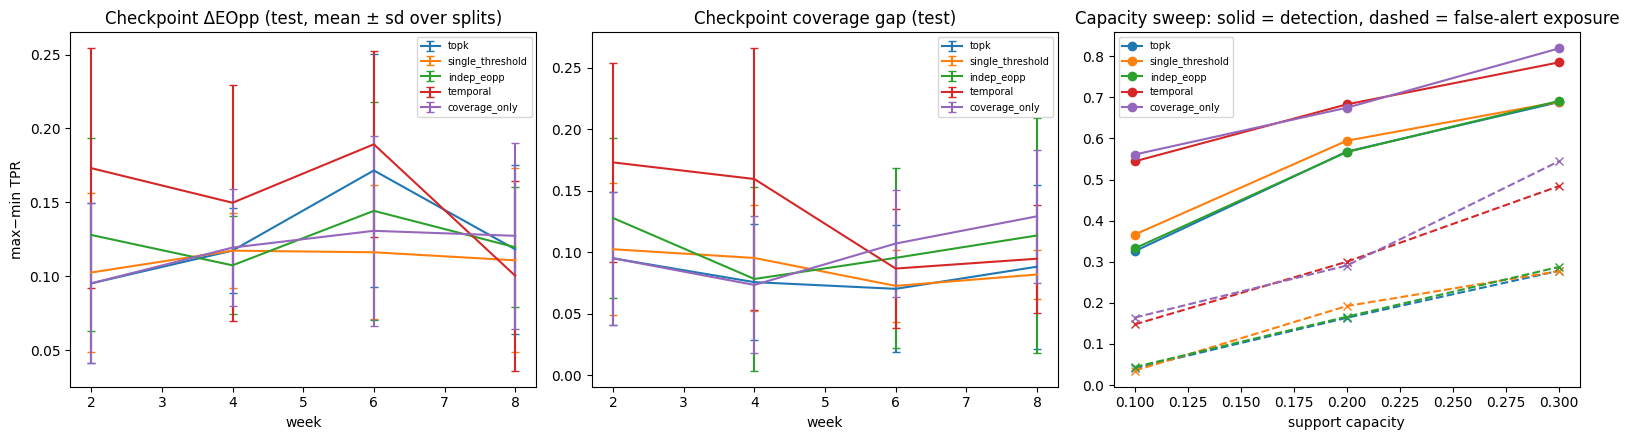

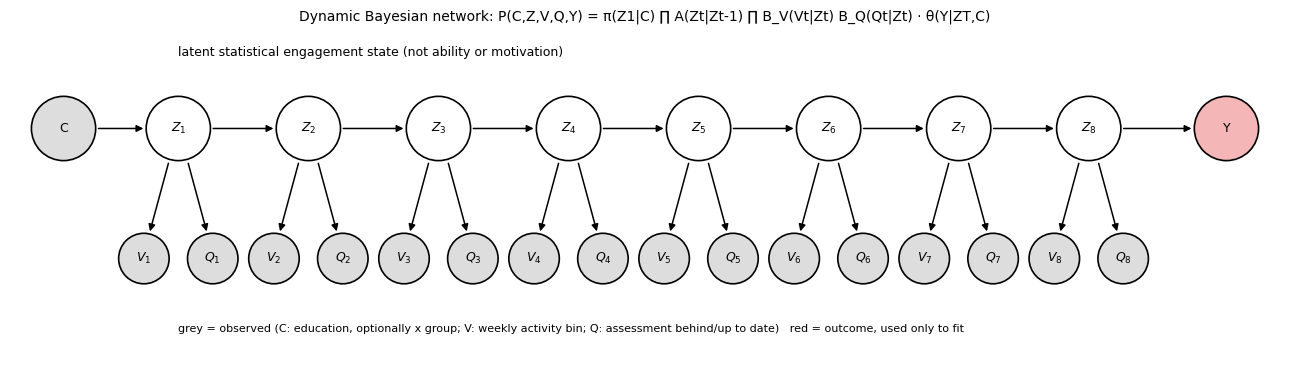

Saved: ['alert_policy_simulation_test.csv', 'dbn_diagram.pdf', 'group_input_alert_changes.csv', 'logloss_brier.csv', 'model_seeds.csv', 'paired_bootstrap_all_splits.csv', 'temporal_fairness.pdf']


In [ ]:
# ===== CELL I: save figures (PDF) for LaTeX =====
R_test = R[(R.set == "test") & (R.capacity == CAP)]
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for pn in POLS:
    dd = R_test[R_test.policy == pn]
    ax[0].errorbar(CK, [dd[f"dEOpp_c{j}"].mean() for j in range(len(CK))],
                   yerr=[dd[f"dEOpp_c{j}"].std() for j in range(len(CK))], label=pn, capsize=3)
    ax[1].errorbar(CK, [dd[f"covgap_c{j}"].mean() for j in range(len(CK))],
                   yerr=[dd[f"covgap_c{j}"].std() for j in range(len(CK))], label=pn, capsize=3)
ax[0].set(title="Checkpoint ΔEOpp (test, mean ± sd over splits)", xlabel="week", ylabel="max−min TPR")
ax[1].set(title="Checkpoint coverage gap (test)", xlabel="week")
ct = R[R.set == "test"].groupby(["capacity", "policy"])[["cd_final", "fa_expo"]].mean().reset_index()
for pn in POLS:
    q = ct[ct.policy == pn]
    ax[2].plot(q.capacity, q.cd_final, "-o", label=pn)
    ax[2].plot(q.capacity, q.fa_expo, "--x", color=ax[2].lines[-1].get_color())
ax[2].set(title="Capacity sweep: solid = detection, dashed = false-alert exposure",
          xlabel="support capacity")
for a in ax: a.legend(fontsize=7)
fig.tight_layout(); fig.savefig(RES / "temporal_fairness.pdf", bbox_inches="tight"); plt.show()

# DBN diagram, saved to PDF as well as shown
_real_show = plt.show
plt.show = lambda *a, **k: (plt.savefig(RES / "dbn_diagram.pdf", bbox_inches="tight"),
                            _real_show(*a, **k))
draw_dbn(sets["train"].W)
plt.show = _real_show
print("Saved:", sorted(p.name for p in RES.iterdir()))

In [ ]:
# Editable capacities for the simulation test
TEST_CAPACITIES = [0.15, 0.20, 0.25]
FIXED_MIN_CELL = MIN_CELL  # Kept fixed at the globally configured value (30)

print(f"Running alert policy simulations with FIXED min_cell = {FIXED_MIN_CELL}\n")
sim_results = []

for cap in TEST_CAPACITIES:
    print(f"Simulating capacity: {cap:.0%}")
    df_cap = simulate(names=("topk", "indep_eopp", "temporal"), cap=cap, set_name="test")
    sim_results.append(df_cap)

sim_combined = pd.concat(sim_results, ignore_index=True)

# Display summary statistics
summary_view = sim_combined.groupby(["capacity", "policy"])[["cum_detection", "cum_coverage_gap", "checkpoint_dEOpp"]].mean().round(3)
display(summary_view)

Running alert policy simulations with FIXED min_cell = 30

Simulating capacity: 15%
Simulating capacity: 20%
Simulating capacity: 25%


cum_detection  cum_coverage_gap  checkpoint_dEOpp
capacity policy                                                       
0.15     indep_eopp          0.375             0.233             0.162
         temporal            0.524             0.081             0.089
         topk                0.371             0.089             0.110
0.20     indep_eopp          0.468             0.220             0.130
         temporal            0.572             0.174             0.087
         topk                0.472             0.109             0.154
0.25     indep_eopp          0.532             0.156             0.137
         temporal            0.531             0.170             0.134
         topk                0.534             0.152             0.112